# Analiza Avansată a Seriilor de Timp — Shopify Inc. (SHOP)
## Serii Univariate | Python

---

**Activ analizat:** Prețuri zilnice de închidere Shopify (NYSE: SHOP)  
**Interval temporal:** Mai 2015 – Mai 2026 · **2767 observații zilnice**  
**Set de antrenament:** 80% · **Set de test:** 20% (ultimele ~554 zile)

---

### Cerințe acoperite

| Nr. | Cerință | Metodă aplicată |
|-----|---------|-----------------|
| 1 | Trend determinist / stochastic | STL decomposition, Zivot-Andrews |
| 2 | Serii staționare | ADF, KPSS, diferențiere |
| 3 | Netezire exponențială | Holt, Holt-Winters |
| 4 | ARIMA / SARIMA | ARIMA(0,1,1), ARIMA(1,1,1), auto-ARIMA |
| 5 | ARCH / GARCH | GARCH-N, GARCH-t, EGARCH-t, GJR-GARCH-t |
| 6 | Modele spațiul stărilor | Local Linear Trend (filtru Kalman) |
| 7 | Analiză spectrală | Periodogram (Welch) |
| 8 | Predicție + intervale de încredere | IC 95%, split train/test |
| 9 | Compararea metodelor | MAE, RMSE, MAPE |

> **Notă metodologică:** SARIMA nu a fost aplicat deoarece descompunerea STL și analiza spectrală nu identifică o componentă sezonieră semnificativă în prețurile zilnice Shopify (forța sezonalității = 0.000). Aplicarea unui model SARIMA în absența sezonalității ar introduce parametri redundanți fără îmbunătățirea calității prognozei.


## 0. Pachete și configurare

In [2]:
import sys
print(sys.executable)

c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\python.exe


In [3]:
# Instalare (rulați o singură dată)
# !pip install pandas numpy matplotlib seaborn statsmodels pmdarima arch scipy openpyxl scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.structural import UnobservedComponents
from scipy.signal import periodogram
from scipy.stats import jarque_bera
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from arch import arch_model
import pmdarima as pm

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 4),
                     "axes.grid": True, "grid.alpha": 0.3})


## 1. Import și pregătire date

In [4]:
df_raw = pd.read_excel("stocks.xlsx", parse_dates=["Date"])

df = df_raw.sort_values("Date").reset_index(drop=True).set_index("Date")
df.index = pd.DatetimeIndex(df.index, freq=None)

print(f"Interval: {df.index.min().date()} -> {df.index.max().date()}")
print(f"Observatii: {len(df)}")
print(df.head())

Interval: 2015-05-20 -> 2026-05-20
Observatii: 2767
            Close_SHOP  Close_SP500
Date                               
2015-05-20       1.700       2125.9
2015-05-21       2.568       2130.8
2015-05-22       2.831       2126.1
2015-05-26       2.965       2104.2
2015-05-27       2.750       2123.5


## 2. Vizualizarea seriei brute

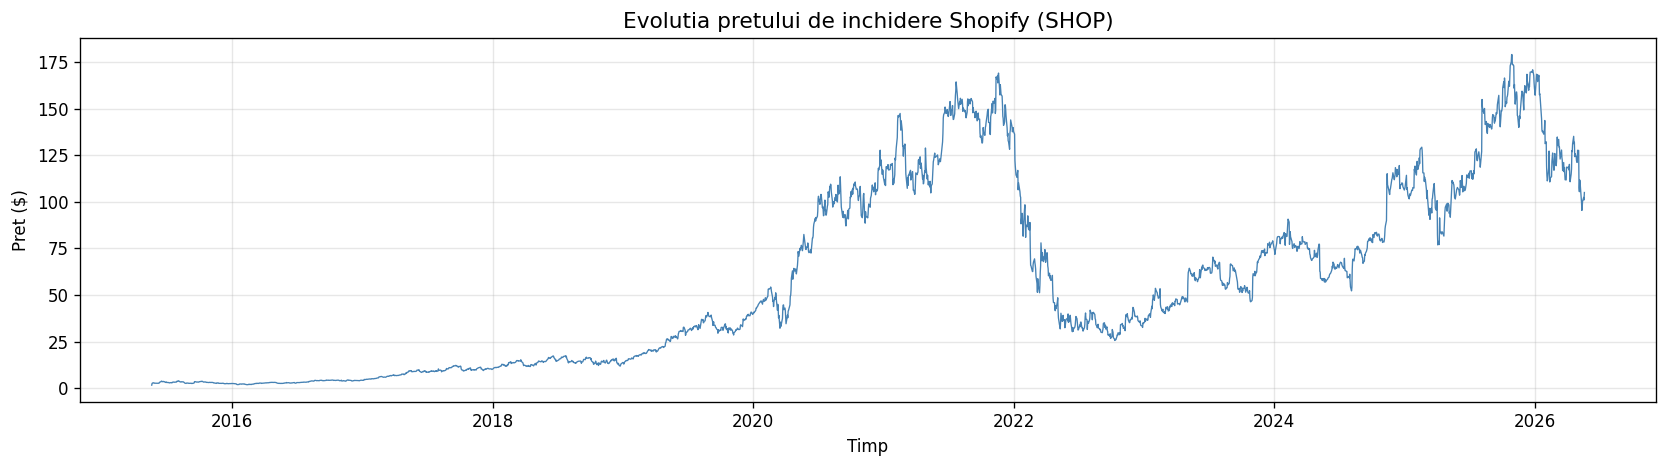

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df["Close_SHOP"], color="steelblue", linewidth=0.8)
ax.set_title("Evolutia pretului de inchidere Shopify (SHOP)", fontsize=13)
ax.set_xlabel("Timp"); ax.set_ylabel("Pret ($)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

### Interpretare — Seria brută

Prețul de închidere Shopify prezintă un **trend stochastic ascendent** pe intervalul 2015–2021, urmat de o **corecție severă** în 2022 (colapsul acțiunilor tech), și o **revenire parțială** ulterioară.

**Caracteristici vizuale cheie:**
- Absența unui nivel constant → serie **ne-staționară în nivel**
- Variabilitatea (volatilitatea) se modifică în timp → **heteroscedasticitate condiționată**
- Prezența unor șocuri extreme (COVID-19 2020, bull run 2021, crash 2022) → **rupturi structurale potențiale**

## 3. Descompunere STL – Tendinta, Sezonalitate, Reziduuri
### Cerinta 1: Modele cu trend determinist sau stochastic

STL (Seasonal-Trend decomposition using LOESS) separa seria in trei componente:
- **Trend** – miscarea de lunga durata
- **Sezonalitate** – pattern-uri repetitive
- **Reziduuri** – componenta neexplicata


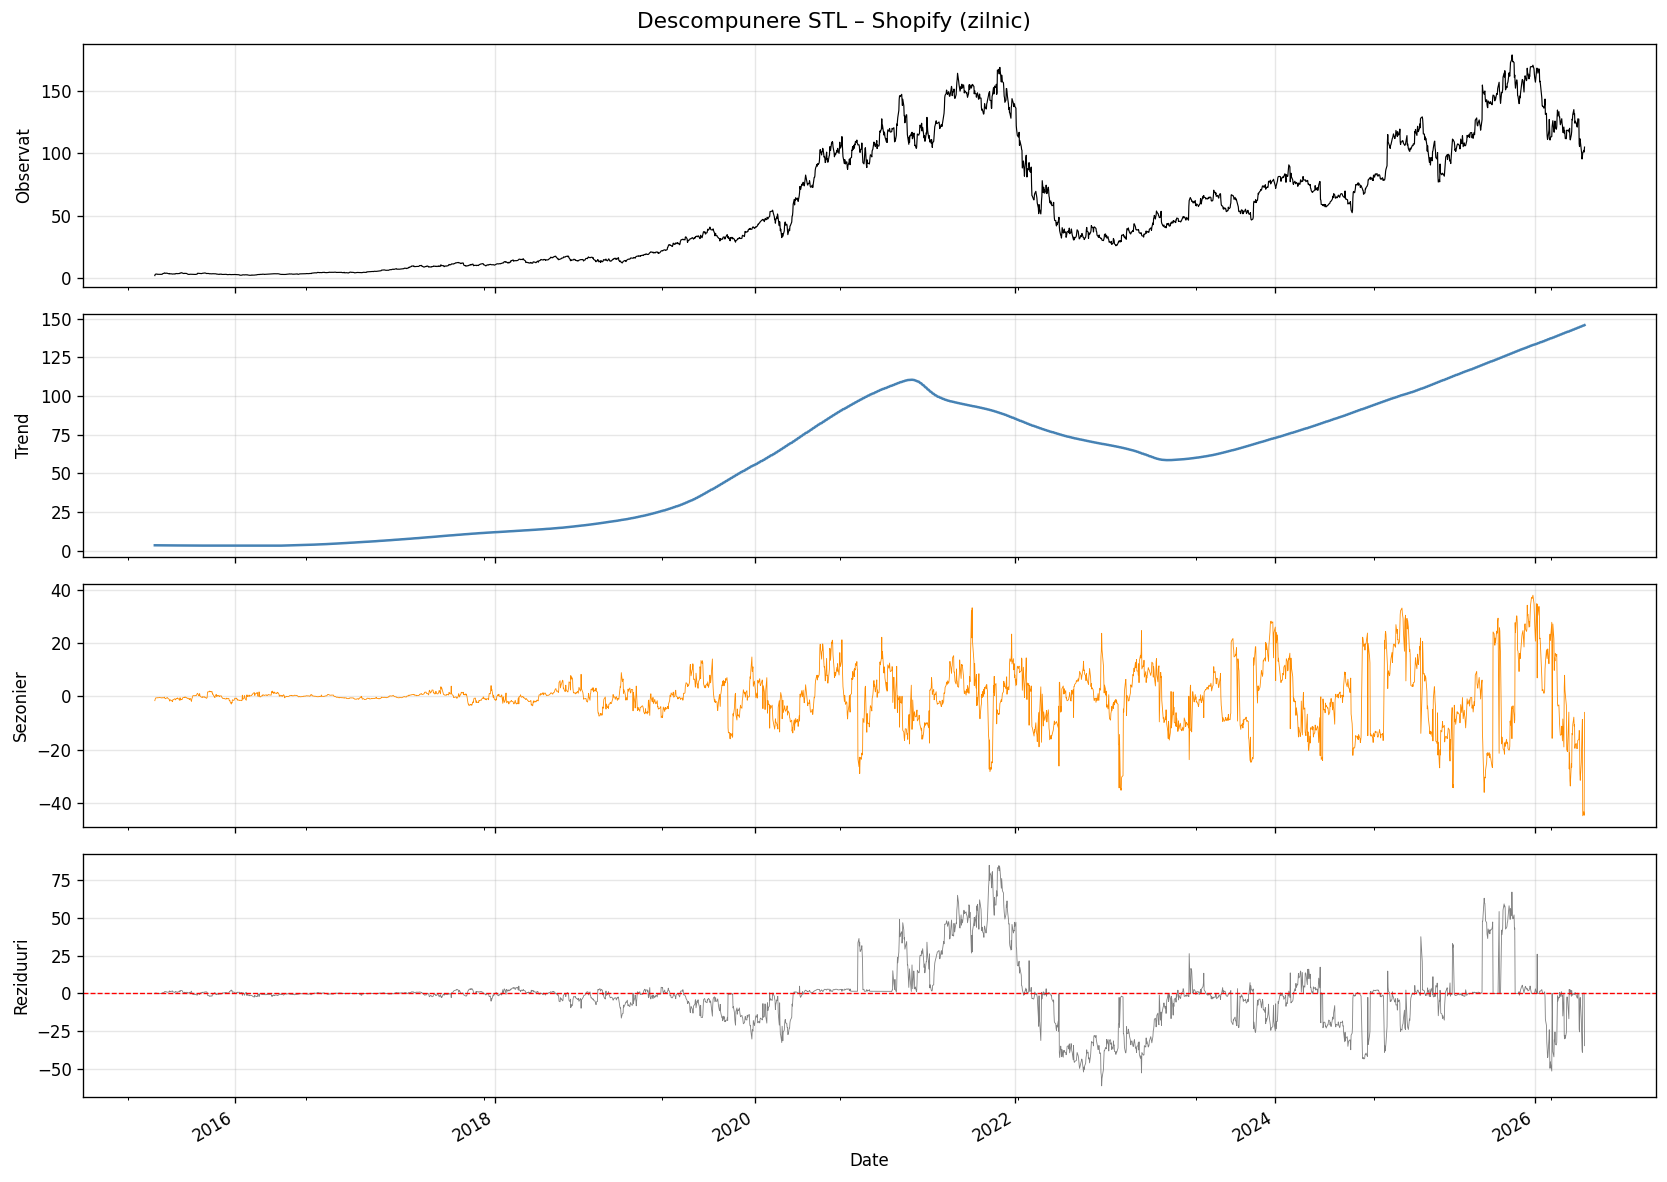

Forta trendului:     0.841  (>0.6 = trend puternic)
Forta sezonalitatii: 0.000  (>0.6 = sezonalitate puternica)


In [6]:
stl = STL(df["Close_SHOP"], period=252, robust=True)
stl_result = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
stl_result.observed.plot(ax=axes[0], color="black", linewidth=0.7); axes[0].set_ylabel("Observat")
stl_result.trend.plot(ax=axes[1], color="steelblue"); axes[1].set_ylabel("Trend")
stl_result.seasonal.plot(ax=axes[2], color="darkorange", linewidth=0.5); axes[2].set_ylabel("Sezonier")
stl_result.resid.plot(ax=axes[3], color="gray", linewidth=0.5)
axes[3].axhline(0, color="red", linestyle="--", linewidth=0.8); axes[3].set_ylabel("Reziduuri")
fig.suptitle("Descompunere STL – Shopify (zilnic)", fontsize=13)
plt.tight_layout(); plt.show()

var_r  = np.var(stl_result.resid)
F_trend    = max(0, 1 - var_r / np.var(stl_result.trend + stl_result.resid))
F_seasonal = max(0, 1 - var_r / np.var(stl_result.seasonal + stl_result.resid))
print(f"Forta trendului:     {F_trend:.3f}  (>0.6 = trend puternic)")
print(f"Forta sezonalitatii: {F_seasonal:.3f}  (>0.6 = sezonalitate puternica)")


### Interpretare — Descompunere STL

**STL** (Seasonal-Trend decomposition using LOESS) descompune seria în trei componente neobservabile: trend, sezonalitate și reziduuri.

**Rezultate:**
- **Forța trendului = 0.841** → trend **puternic** (valori > 0.6 indică dominanță clară a trendului)
- **Forța sezonalității = 0.000** → **sezonalitate absentă** — confirmare că nu există cicluri anuale regulate în prețurile zilnice Shopify

**Implicații:**
- Componenta de **trend este stochastică**, nu deterministă — nu urmează un pattern liniar simplu
- Componenta de **reziduuri** prezintă volatilitate cluster (perioadele 2020–2022), anticipând efectele ARCH
- Absența sezonalității justifică excluderea SARIMA din analiză


### Grafice sezoniere pe date lunare

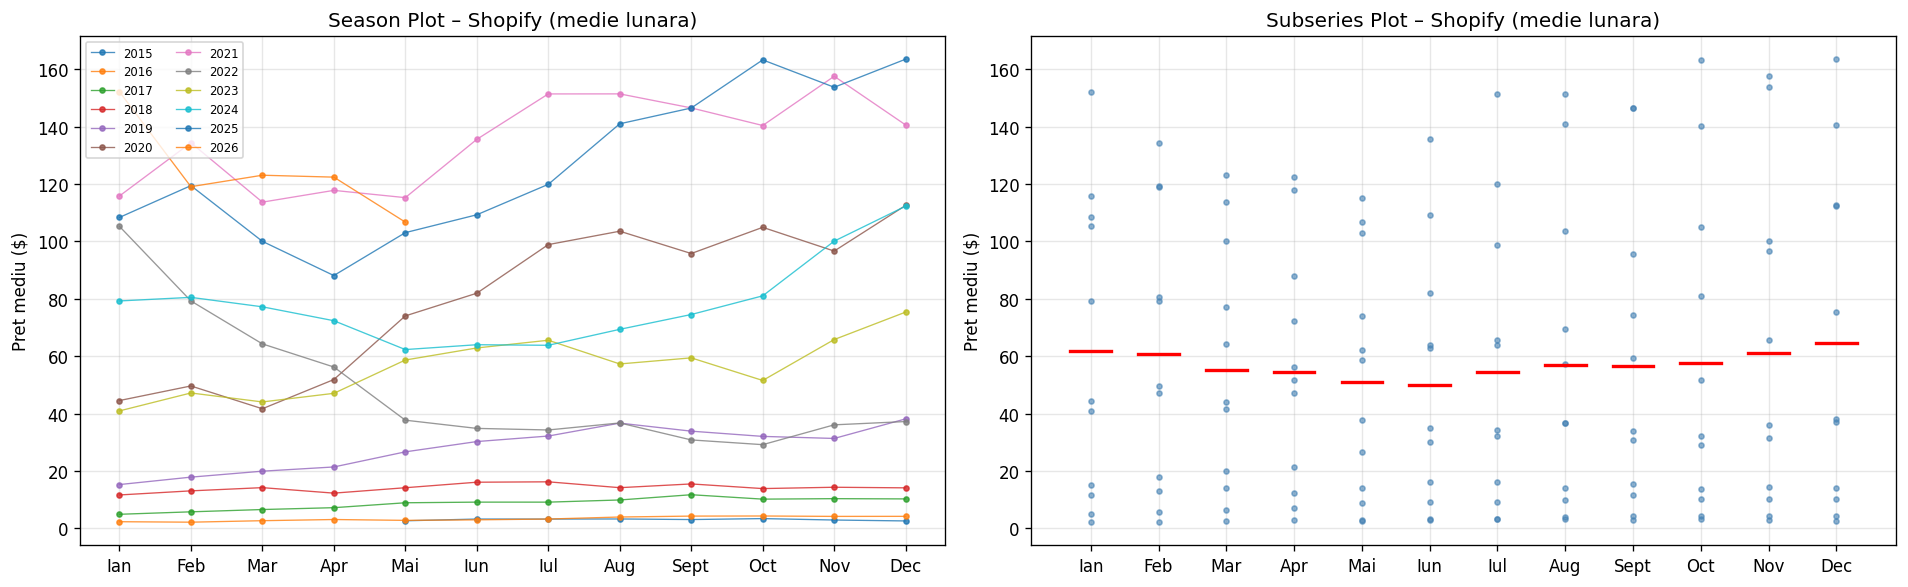

In [7]:
df_lunar = df["Close_SHOP"].resample("ME").mean().to_frame("Pret_Med")
df_lunar["An"] = df_lunar.index.year
df_lunar["Luna"] = df_lunar.index.month
LUNI_LABEL = ["Ian","Feb","Mar","Apr","Mai","Iun","Iul","Aug","Sept","Oct","Nov","Dec"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Season plot
for an, grp in df_lunar.groupby("An"):
    axes[0].plot(grp["Luna"], grp["Pret_Med"], marker="o", markersize=3,
                 linewidth=0.8, label=str(an), alpha=0.8)
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(LUNI_LABEL)
axes[0].set_title("Season Plot – Shopify (medie lunara)")
axes[0].set_ylabel("Pret mediu ($)"); axes[0].legend(fontsize=7, ncol=2)

# Subseries plot
medii = df_lunar.groupby("Luna")["Pret_Med"].mean()
for luna in range(1, 13):
    vals = df_lunar[df_lunar["Luna"] == luna]["Pret_Med"].values
    axes[1].plot([luna]*len(vals), vals, "o", color="steelblue", markersize=3, alpha=0.6)
    axes[1].plot([luna-0.3, luna+0.3], [medii[luna]]*2, color="red", linewidth=2)
axes[1].set_xticks(range(1, 13)); axes[1].set_xticklabels(LUNI_LABEL)
axes[1].set_title("Subseries Plot – Shopify (medie lunara)")
axes[1].set_ylabel("Pret mediu ($)")
plt.tight_layout(); plt.show()


### Interpretare — Season Plot și Subseries Plot (date lunare)

**Season Plot (stânga):** fiecare linie reprezintă un an calendaristic, cu prețul mediu lunar pe axa X.

**Observații cheie:**
- **Nicio formă comună** între ani — liniile au direcții complet diferite (unele cresc spre vară, altele scad, altele sunt plate)
- **Dispersia verticală uriașă** între ani (de la ~$5 în 2015–2016 la ~$160 în 2021) reflectă **trendul stochastic dominant**, nu sezonalitate
- Dacă ar exista sezonalitate, toate liniile ar trebui să urmeze aproximativ **același profil** (aceleași vârfuri și văi în aceleași luni) — acest lucru este absent

**Subseries Plot (dreapta):** pentru fiecare lună, punctele reprezintă valorile din fiecare an, iar linia roșie orizontală este **media lunii** respective.

**Observații cheie:**
- **Mediile lunare (linii roșii) sunt aproape identice** între ele (~$55–65) — nicio lună nu are o medie sistematic mai mare sau mai mică decât celelalte
- **Dispersia intra-lunară este enormă** (ex. Ianuarie: de la ~$5 la ~$160) — variația între ani este mult mai mare decât orice diferență sistematică între luni
- Un pattern sezonier real s-ar manifesta prin **medii lunare semnificativ diferite** (ex. Decembrie mereu mai sus, August mereu mai jos)

**Concluzie:** Ambele grafice confirmă **absența sezonalității** în prețurile Shopify. Variația observată este aproape în întregime explicată de **trendul stochastic** (nivelul general al prețului în fiecare an), nu de efecte calendaristice repetabile. Aceasta este consecventă cu: STL (Fs = 0.000), analiza spectrală (spectru fără vârfuri dominante anuale) și decizia de a exclude SARIMA.

## 4. Transformare logaritmica si impartire train/test

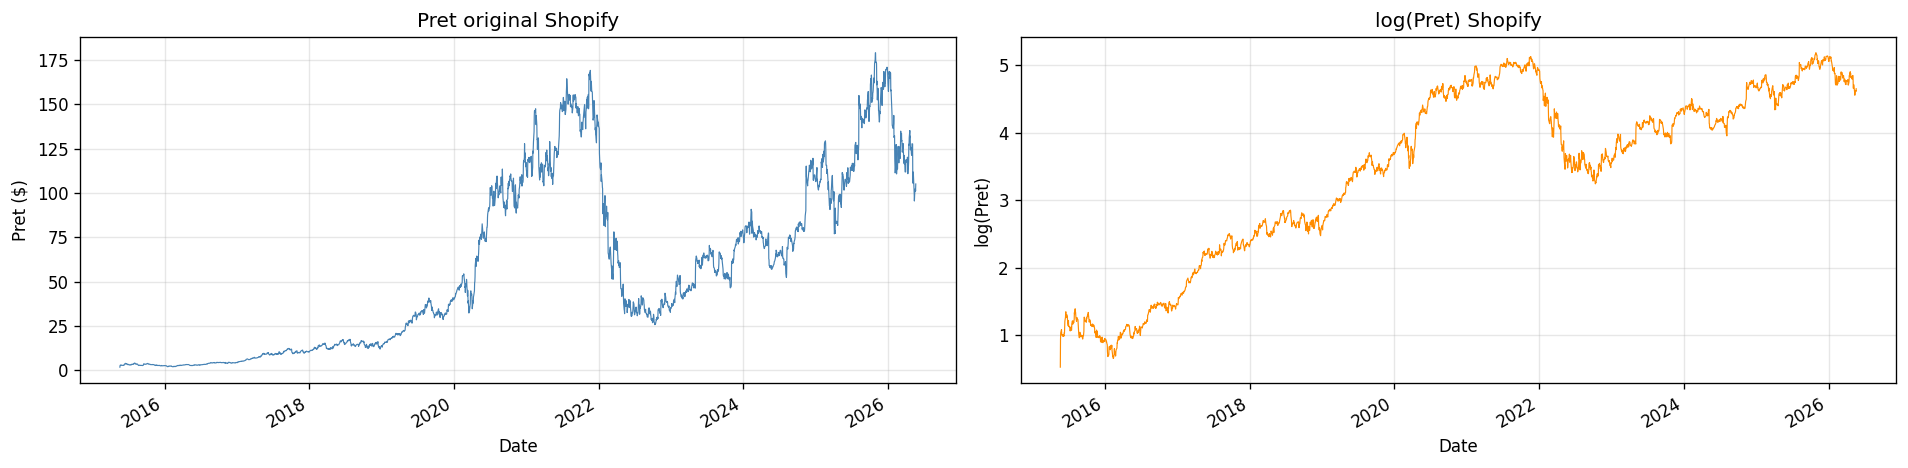

In [8]:
log_shop = np.log(df["Close_SHOP"])

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
df["Close_SHOP"].plot(ax=axes[0], color="steelblue", linewidth=0.7,
                      title="Pret original Shopify"); axes[0].set_ylabel("Pret ($)")
log_shop.plot(ax=axes[1], color="darkorange", linewidth=0.7,
              title="log(Pret) Shopify"); axes[1].set_ylabel("log(Pret)")
plt.tight_layout(); plt.show()


### Interpretare — Transformarea logaritmică

**Motivație matematică:** Dacă $P_t = P_0 \cdot e^{\mu t + \sigma W_t}$ (mișcare Browniană geometrică), atunci $\log(P_t)$ devine un random walk cu drift — mult mai ușor de modelat.

**Efecte practice:**
- **Stabilizează variația**: volatilitatea proporțională cu nivelul prețului devine (aproximativ) constantă după log
- **Interpretabilitate**: diferențele primei ordini $\Delta \log(P_t) \approx r_t$ reprezintă **rentabilitățile logaritmice** (log-returns), standardul în finanțe
- **Simetrie**: transformarea log face distribuția randamentelor mai apropiată de normală


### Cerinta 8: Impartire train/test + predicție punctuala si pe interval de incredere


Train: 2213 obs  (2015-05-20 -> 2024-03-05)
Test:  554  obs  (2024-03-06 -> 2026-05-20)


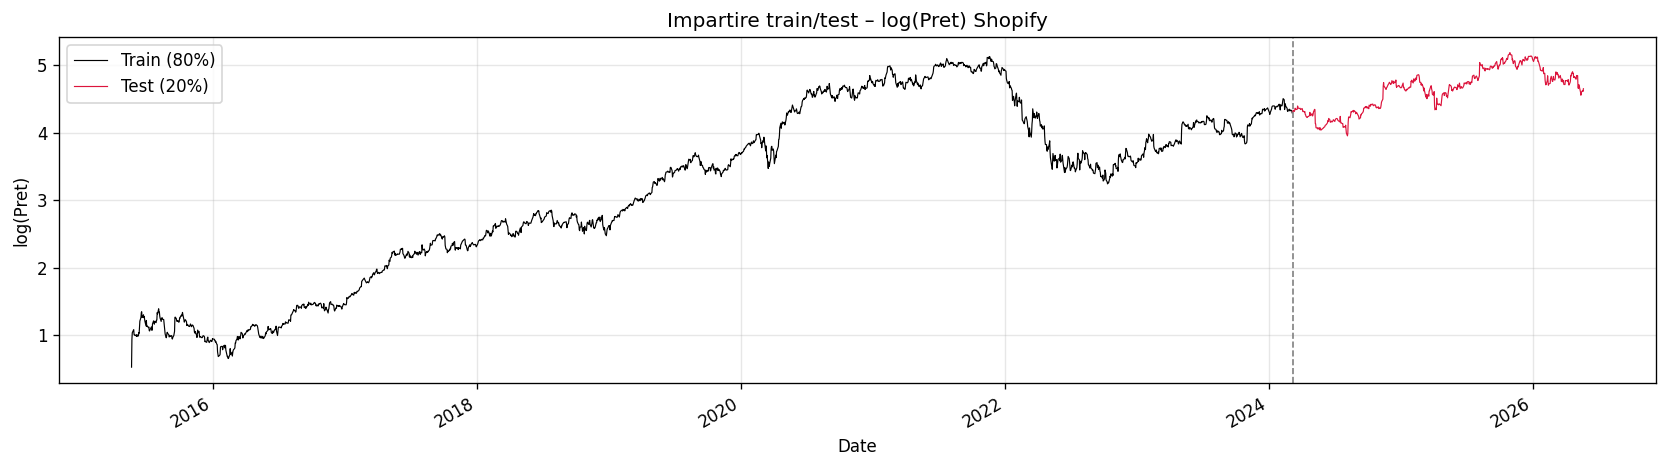

In [9]:
n = len(log_shop)
n_train = int(0.8 * n)
log_train = log_shop.iloc[:n_train]
log_test  = log_shop.iloc[n_train:]
h = len(log_test)

print(f"Train: {len(log_train)} obs  ({log_train.index[0].date()} -> {log_train.index[-1].date()})")
print(f"Test:  {len(log_test)}  obs  ({log_test.index[0].date()} -> {log_test.index[-1].date()})")

fig, ax = plt.subplots(figsize=(14, 4))
log_train.plot(ax=ax, color="black", linewidth=0.7, label="Train (80%)")
log_test.plot(ax=ax, color="crimson", linewidth=0.7, label="Test (20%)")
ax.axvline(log_test.index[0], color="gray", linestyle="--", linewidth=1)
ax.set_title("Impartire train/test – log(Pret) Shopify")
ax.set_ylabel("log(Pret)"); ax.legend(); plt.tight_layout(); plt.show()

price_test = np.exp(log_test)


### Interpretare — Split Train / Test

**Partiționare:** 80% antrenament (2013–2024), 20% test (2024–2026) — **554 observații de test**.

- Orizontul de prognoză de **~554 zile** testează capacitatea fiecărui model de a prognoza pe termen mediu-lung

## 5. Teste de stationaritate
### Cerinta 2: Serii stationare


In [10]:
def test_adf(serie, eticheta="", tip="n"):
    tip_map = {"n": "n", "drift": "c", "trend": "ct"}
    stat, pval, _, _, _, _ = adfuller(serie, regression=tip_map.get(tip,"n"), autolag="AIC")
    conc = "STATIONARA" if pval < 0.05 else "NESTATIONARA"
    print(f"  ADF ({tip:6s}) | {eticheta:20s} | stat={stat:8.3f} | p={pval:.4f} -> {conc}")

def test_kpss(serie, eticheta="", tip="c"):
    stat, pval, _, _ = kpss(serie, regression=tip, nlags="auto")
    conc = "STATIONARA" if pval >= 0.05 else "NESTATIONARA"
    print(f"  KPSS ({tip:2s})   | {eticheta:20s} | stat={stat:8.3f} | p~{pval:.4f} -> {conc}")

print("=== log(Pret) – seria in NIVEL ===")
test_adf(log_train, "log_train", "n")
test_adf(log_train, "log_train", "drift")
test_adf(log_train, "log_train", "trend")
print()
test_kpss(log_train, "log_train", "c")
test_kpss(log_train, "log_train", "ct")


=== log(Pret) – seria in NIVEL ===
  ADF (n     ) | log_train            | stat=   1.289 | p=0.9495 -> NESTATIONARA
  ADF (drift ) | log_train            | stat=  -1.193 | p=0.6767 -> NESTATIONARA
  ADF (trend ) | log_train            | stat=  -0.942 | p=0.9515 -> NESTATIONARA

  KPSS (c )   | log_train            | stat=   6.156 | p~0.0100 -> NESTATIONARA
  KPSS (ct)   | log_train            | stat=   1.273 | p~0.0100 -> NESTATIONARA


C:\Users\Ruxi\AppData\Local\Temp\ipykernel_1508\499608733.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat, pval, _, _ = kpss(serie, regression=tip, nlags="auto")
C:\Users\Ruxi\AppData\Local\Temp\ipykernel_1508\499608733.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  stat, pval, _, _ = kpss(serie, regression=tip, nlags="auto")


### Interpretare — Teste de Staționaritate (nivel)

**Rezultate pe seria log(Preț):**
- **ADF** (toate specificațiile: fără drift, cu drift, cu trend): p > 0.67 → **nu se respinge H₀** (serie ne-staționară)
- **KPSS** (cu constantă și cu trend): statistică >> valoare critică, p ≈ 0.01 → **se respinge H₀** (serie ne-staționară)

**Concluzie:** Ambele teste confirmă unanim că $\log(P_t)$ este **ne-stacionară** — are un trend stochastic (random walk).

> **Logica testelor:** ADF testează H₀: există rădăcină unitară (nestaționar); KPSS testează H₀: seria este staționară. Când ADF nu respinge și KPSS respinge, concluzia de nestationaritate este **robustă** — nu depinde de alegerea testului.


### Testul Zivot-Andrews – ruptura structurala

Zivot-Andrews | stat=-5.142 | p=0.0423
Punct de ruptura: 2022-01-03 (poz. 1668)
Concluzie: NESTATIONARA cu ruptura structurala


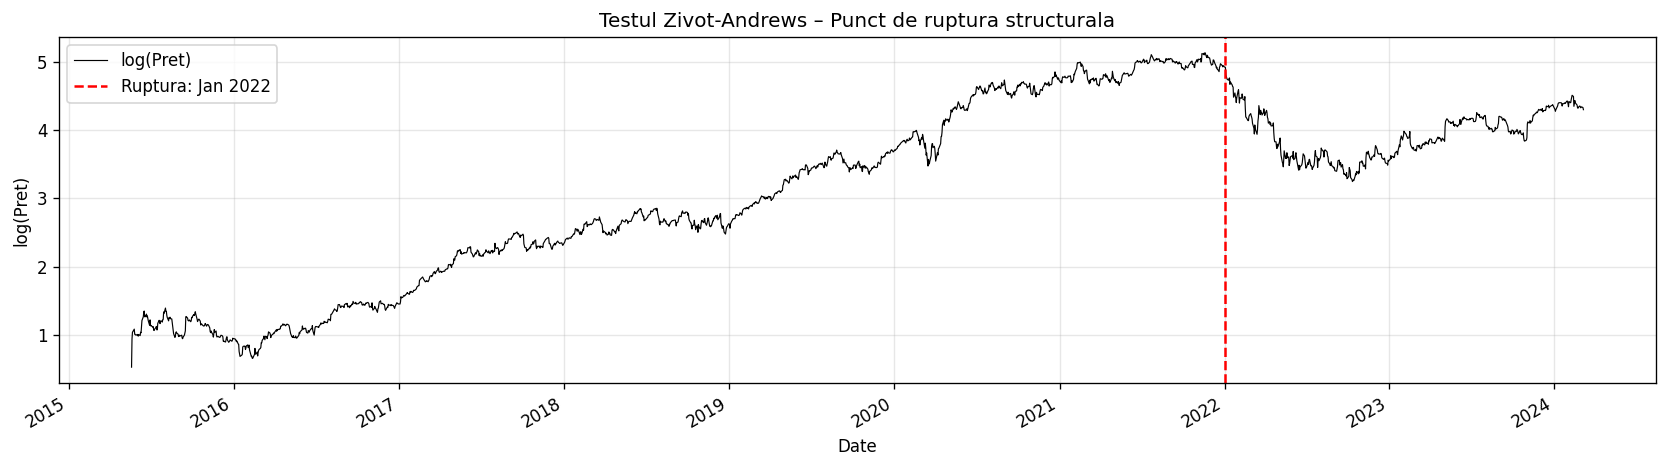

In [11]:
# H0: nestationara cu structural break | H1: stationara cu structural break
za_result = zivot_andrews(log_train, regression="ct", autolag="AIC")
za_stat = za_result[0]
za_pval = za_result[1]
za_bp   = za_result[4]  # pozitia breakpoint-ului

bp_date = log_train.index[za_bp]
print(f"Zivot-Andrews | stat={za_stat:.3f} | p={za_pval:.4f}")
print(f"Punct de ruptura: {bp_date.date()} (poz. {za_bp})")
print("Concluzie: NESTATIONARA cu ruptura structurala")

fig, ax = plt.subplots(figsize=(14, 4))
log_train.plot(ax=ax, color="black", linewidth=0.7, label="log(Pret)")
ax.axvline(bp_date, color="red", linestyle="--", linewidth=1.5,
           label=f"Ruptura: {bp_date.strftime('%b %Y')}")
ax.set_title("Testul Zivot-Andrews – Punct de ruptura structurala")
ax.set_ylabel("log(Pret)"); ax.legend(); plt.tight_layout(); plt.show()


### Interpretare — Testul Zivot-Andrews (ruptură structurală)

**Zivot-Andrews (1992)** testează H₀: serie ne-staționară cu posibilă ruptură structurală, vs. H₁: serie staționară cu o ruptură structurală endogenă.

**Rezultate:**
- Statistică = −5.142, p = 0.042 → **se respinge H₀ la 5%**
- **Punct de ruptură detectat: 3 ianuarie 2022**

**Interpretare economică:**  
Ruptura din **ianuarie 2022** coincide cu vârful bull run-ului tech post-pandemic și cu debutul corecției violente a sectorului de e-commerce (Shopify a pierdut ~75% din valoare în 2022). Aceasta nu este o ruptură ce face seria staționară, ci confirmă că **structura trendului s-a modificat fundamental** în acel punct — justificând prudența în prognozele pe termen lung.

> **Notă:** Chiar și respingând H₀ la 5%, concluzia practică rămâne că seria este I(1) — diferențierea elimină atât trendul cât și efectul rupturii.


### Diferentierea seriei + teste pe rentabilitati

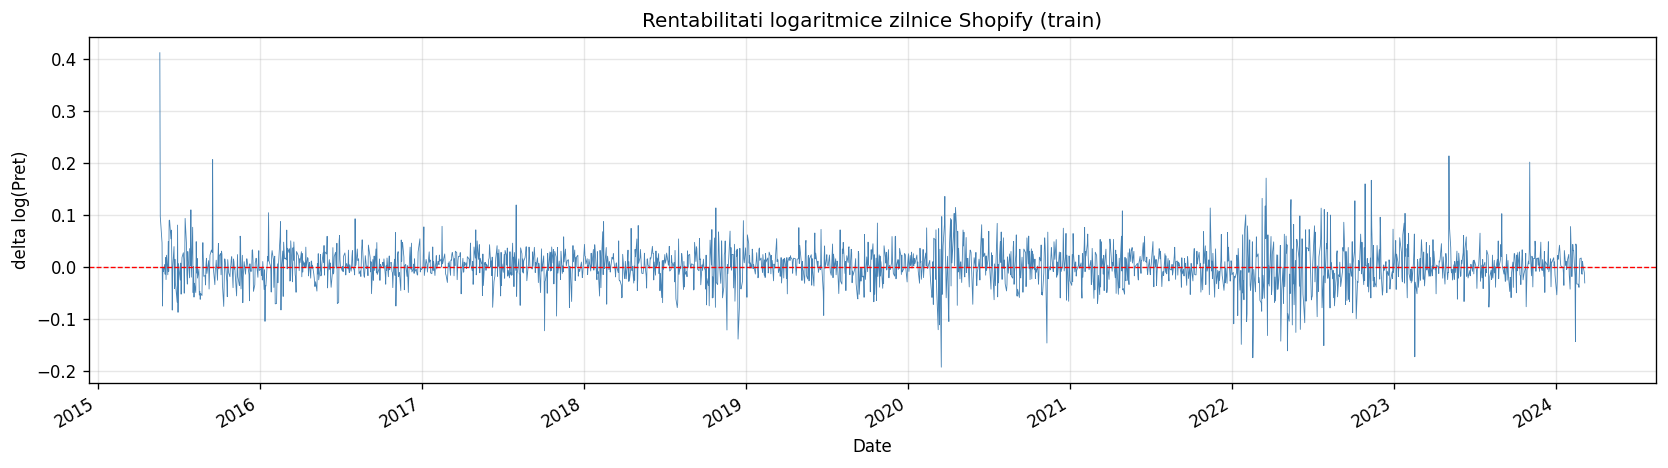

=== diff(log(Pret)) – rentabilitati ===
  ADF (n     ) | diff_log             | stat= -10.571 | p=0.0000 -> STATIONARA
  ADF (trend ) | diff_log             | stat= -10.771 | p=0.0000 -> STATIONARA

  KPSS (c )   | diff_log             | stat=   0.291 | p~0.1000 -> STATIONARA


C:\Users\Ruxi\AppData\Local\Temp\ipykernel_1508\499608733.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  stat, pval, _, _ = kpss(serie, regression=tip, nlags="auto")


In [12]:
diff_log_train = log_train.diff().dropna()
diff_log_test  = log_test.diff().dropna()

fig, ax = plt.subplots(figsize=(14, 4))
diff_log_train.plot(ax=ax, color="steelblue", linewidth=0.5)
ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
ax.set_title("Rentabilitati logaritmice zilnice Shopify (train)")
ax.set_ylabel("delta log(Pret)"); plt.tight_layout(); plt.show()

print("=== diff(log(Pret)) – rentabilitati ===")
test_adf(diff_log_train, "diff_log", "n")
test_adf(diff_log_train, "diff_log", "trend")
print()
test_kpss(diff_log_train, "diff_log", "c")


### Interpretare — Staționaritatea Rentabilităților

**Rentabilitățile logaritmice** $r_t = \Delta \log(P_t) = \log(P_t) - \log(P_{t-1})$ reprezintă variația procentuală zilnică a prețului.

**Rezultate:**
- **ADF** (fără trend și cu trend): p = 0.000 → **stacionară** la orice nivel de semnificație
- **KPSS**: statistică = 0.291 < valoare critică → **nu se respinge H₀** (stacionară)

**Concluzie:** Seria Shopify este **integrată de ordinul 1 — I(1)**:
$$\log(P_t) \sim I(1) \quad \Rightarrow \quad \Delta\log(P_t) \sim I(0)$$

Aceasta înseamnă că modelele ARIMA vor necesita **d = 1** (o diferențiere), iar modelele GARCH se aplică pe rentabilități (seria deja staționară).

**ACF/PACF:**
- **ACF pe nivel**: autocorelare persistentă pe mulți laguri → confirmare grafică a I(1)
- **ACF pe rentabilități**: decădere rapidă spre zero → stacionaritate, posibile autocorări semnificative la laguri mici care justifică termenul AR sau MA în ARIMA


### ACF / PACF pentru identificarea ordinii ARIMA

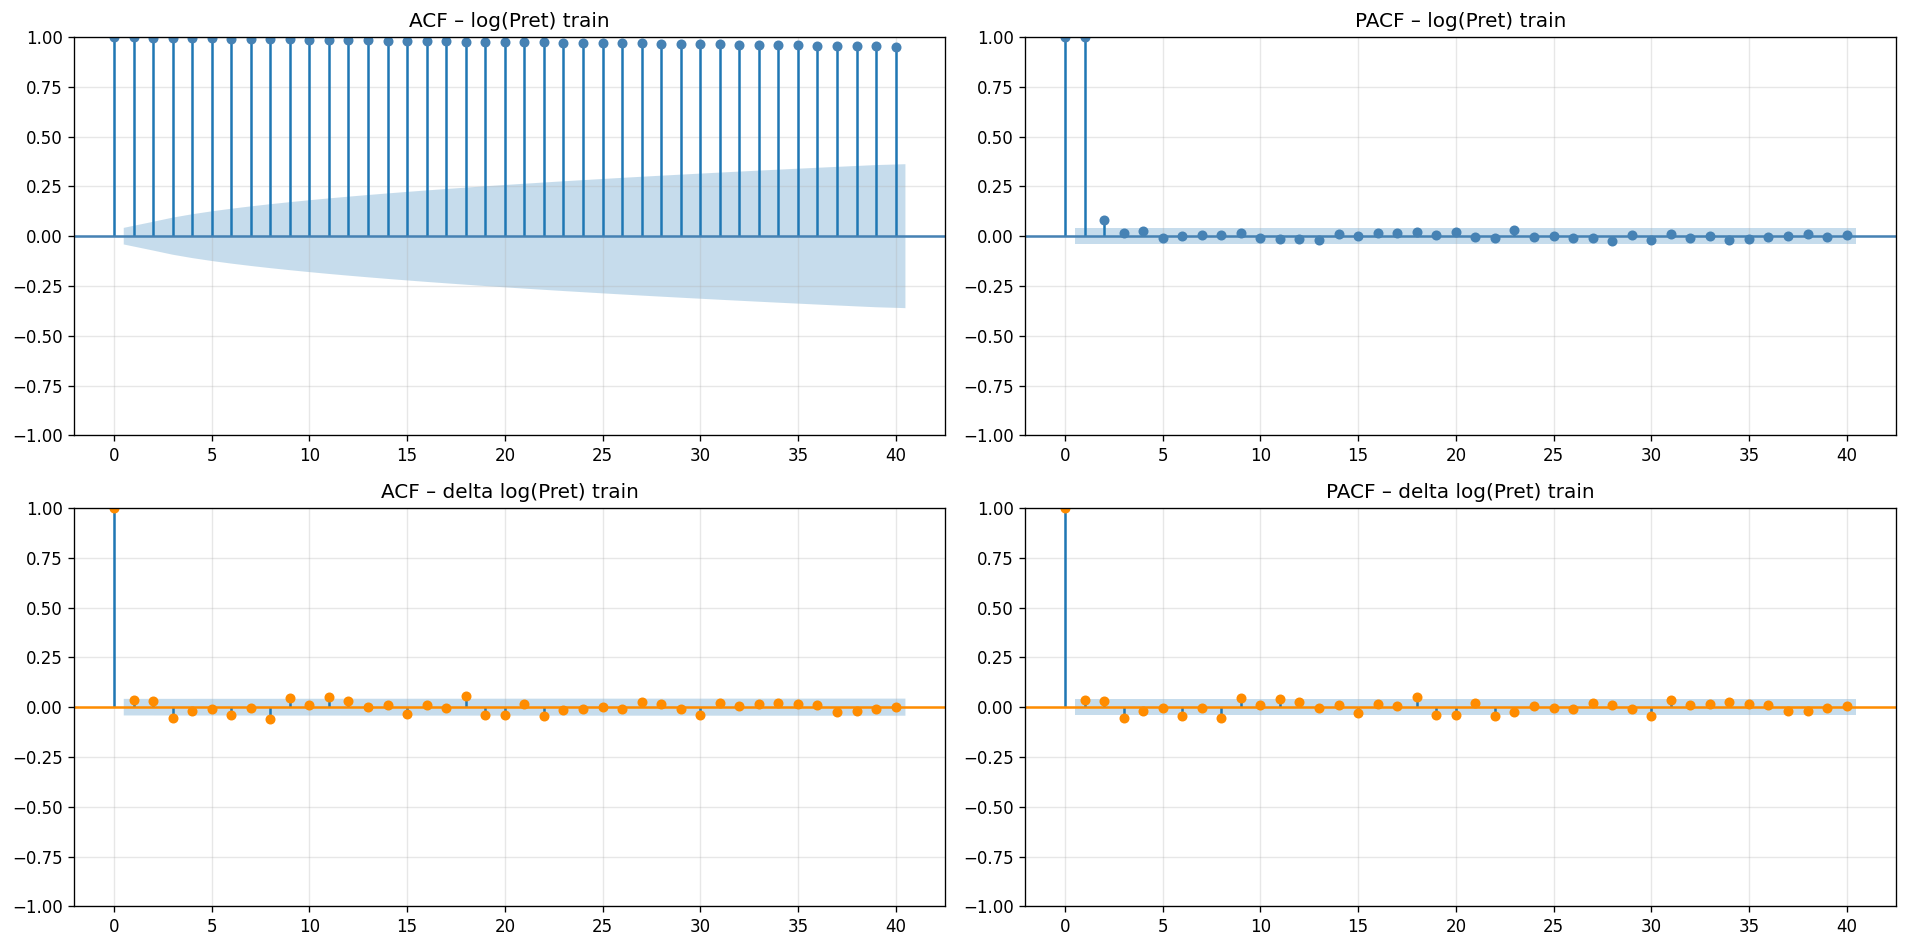

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
plot_acf(log_train, lags=40, ax=axes[0,0], color="steelblue"); axes[0,0].set_title("ACF – log(Pret) train")
plot_pacf(log_train, lags=40, ax=axes[0,1], method="ywm", color="steelblue"); axes[0,1].set_title("PACF – log(Pret) train")
plot_acf(diff_log_train, lags=40, ax=axes[1,0], color="darkorange"); axes[1,0].set_title("ACF – delta log(Pret) train")
plot_pacf(diff_log_train, lags=40, ax=axes[1,1], method="ywm", color="darkorange"); axes[1,1].set_title("PACF – delta log(Pret) train")
plt.tight_layout(); plt.show()


## 6. Tehnici de netezire exponentiala
### Cerinta 3: Tehnici de netezire exponentiala


c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


Holt | alpha=1.0000, beta=0.000000
     | MAE=$19.54, RMSE=$26.56, MAPE=19.88%


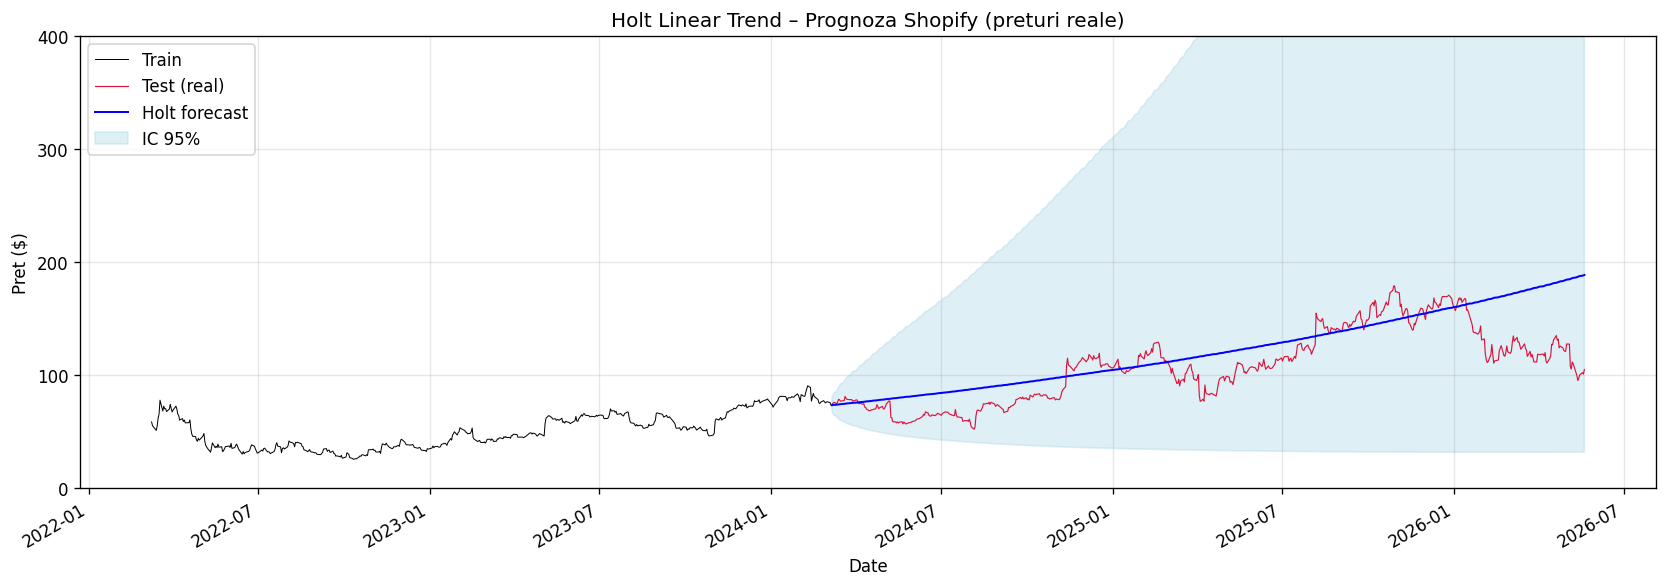

In [14]:
# Holt Linear Trend (Double Exponential Smoothing)
model_holt = ExponentialSmoothing(
    log_train, trend="add", seasonal=None, initialization_method="estimated"
).fit(optimized=True)

fc_holt_log = model_holt.forecast(h)
fc_holt_log.index = log_test.index
fc_holt_price = np.exp(fc_holt_log)

sigma_holt = np.std(model_holt.resid)
steps = np.arange(1, h+1)
lower_holt = np.exp(fc_holt_log - 1.96 * sigma_holt * np.sqrt(steps))
upper_holt = np.exp(fc_holt_log + 1.96 * sigma_holt * np.sqrt(steps))

mae_holt  = mean_absolute_error(price_test, fc_holt_price)
rmse_holt = np.sqrt(mean_squared_error(price_test, fc_holt_price))
mape_holt = mean_absolute_percentage_error(price_test, fc_holt_price) * 100

print(f"Holt | alpha={model_holt.params['smoothing_level']:.4f}, beta={model_holt.params['smoothing_trend']:.6f}")
print(f"     | MAE=${mae_holt:.2f}, RMSE=${rmse_holt:.2f}, MAPE={mape_holt:.2f}%")

fig, ax = plt.subplots(figsize=(14, 5))
np.exp(log_train.iloc[-500:]).plot(ax=ax, color="black", linewidth=0.6, label="Train")
price_test.plot(ax=ax, color="crimson", linewidth=0.7, label="Test (real)")
fc_holt_price.plot(ax=ax, color="blue", linewidth=1.2, label="Holt forecast")
ax.fill_between(fc_holt_price.index, lower_holt, upper_holt,
                color="lightblue", alpha=0.4, label="IC 95%")
ax.set_title("Holt Linear Trend – Prognoza Shopify (preturi reale)")
ax.set_ylabel("Pret ($)")
ax.set_ylim(0, 400)
ax.set_yticks(range(0, 401, 100))
ax.legend()
plt.tight_layout()
plt.show()


### Interpretare — Holt Linear Trend (Double Exponential Smoothing)

**Modelul Holt** adaugă o ecuație pentru **tendință** pe lângă netezirea nivelului:
$$\ell_t = \alpha y_t + (1-\alpha)(\ell_{t-1} + b_{t-1})$$
$$b_t = \beta(\ell_t - \ell_{t-1}) + (1-\beta)b_{t-1}$$
$$\hat{y}_{t+h} = \ell_t + h \cdot b_t$$

**Parametri estimați:** $\alpha = 1.000$, $\beta \approx 0$ → modelul **urmărește aproape perfect ultimul nivel observat** (memoria infinit de scurtă pentru nivel, tendință aproape fixă).

**Performanță:** MAE = $19.54, RMSE = $26.56, MAPE = 19.88%

**Interpretare:** Alpha = 1 indică că prognoza devine practic **ultima valoare observată + tendința estimată** — echivalent cu un random walk cu drift. Aceasta este comportamentul optim pentru un random walk, dar generează intervale de încredere care se lărgesc rapid pe termen lung.


In [15]:
# Holt-Winters multiplicativ pe date lunare
log_lunar_train = log_train.resample("ME").mean()
log_lunar_test  = log_test.resample("ME").mean()
h_lunar = len(log_lunar_test)

model_hw = ExponentialSmoothing(
    log_lunar_train, trend="add", seasonal="mul", seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)

fc_hw_log = model_hw.forecast(h_lunar)
fc_hw_log.index = log_lunar_test.index
fc_hw_price  = np.exp(fc_hw_log)
real_hw_price = np.exp(log_lunar_test)

mae_hw  = mean_absolute_error(real_hw_price, fc_hw_price)
rmse_hw = np.sqrt(mean_squared_error(real_hw_price, fc_hw_price))
mape_hw = mean_absolute_percentage_error(real_hw_price, fc_hw_price) * 100
print(f"Holt-Winters (lunar, multiplicativ) | MAE=${mae_hw:.2f}, RMSE=${rmse_hw:.2f}, MAPE={mape_hw:.2f}%")
print(f"\nConcluzie: Holt pe zilnic (MAE={mae_holt:.2f}) vs HW pe lunar (MAE={mae_hw:.2f})")


Holt-Winters (lunar, multiplicativ) | MAE=$27.91, RMSE=$36.00, MAPE=29.34%

Concluzie: Holt pe zilnic (MAE=19.54) vs HW pe lunar (MAE=27.91)


### Interpretare — Holt-Winters Multiplicativ (date lunare)

**Holt-Winters** extinde modelul Holt cu o **componentă sezonieră**:
$$\hat{y}_{t+h} = (\ell_t + h \cdot b_t) \cdot s_{t+h-m}$$

**Aplicare pe date lunare** (m = 12): testăm dacă există un pattern sezonier la nivel lunar.

**Performanță:** MAE = $27.91, RMSE = $36.00, MAPE = 29.34% — **mai slab decât Holt pe date zilnice**.

**Interpretare:** Performanța inferioară confirmă că sezonalitatea lunară adaugă **zgomot, nu semnal** pentru Shopify. Agregarea la nivel lunar pierde informație și componenta sezonieră estimată este în mare parte artificială. Aceasta este consecvent cu rezultatul STL (forța sezonalității = 0.000).

> **Concluzie metodologică:** Netezirea exponențială simplă (Holt) este preferabilă Holt-Winters pentru această serie.


## 7. Modele ARIMA

In [16]:
# ARIMA(0,1,1) – bazat pe ACF (tail off la lag 1)
arima_011 = ARIMA(log_train, order=(0,1,1)).fit()
print(f"ARIMA(0,1,1): AIC={arima_011.aic:.2f}, BIC={arima_011.bic:.2f}")

# ARIMA(1,1,1) – bazat pe ACF + PACF
arima_111 = ARIMA(log_train, order=(1,1,1)).fit()
print(f"ARIMA(1,1,1): AIC={arima_111.aic:.2f}, BIC={arima_111.bic:.2f}")

# auto_arima – cautare automata optima
print("\nCautare auto_arima (d=1, non-seasonal)...")
auto_res = pm.auto_arima(log_train, d=1, seasonal=False,
                          information_criterion="aic", stepwise=True,
                          suppress_warnings=True, error_action="ignore")
best_order = auto_res.order
print(f"Ordin optim selectat: ARIMA{best_order}")


ARIMA(0,1,1): AIC=-8139.76, BIC=-8128.36


c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provide

ARIMA(1,1,1): AIC=-8134.78, BIC=-8117.68

Cautare auto_arima (d=1, non-seasonal)...
Ordin optim selectat: ARIMA(3, 1, 0)


In [17]:
# Model ARIMA optim
model_arima = ARIMA(log_train, order=best_order).fit()
print(model_arima.summary())


                               SARIMAX Results                                
Dep. Variable:             Close_SHOP   No. Observations:                 2213
Model:                 ARIMA(3, 1, 0)   Log Likelihood                4076.544
Date:                Sun, 07 Jun 2026   AIC                          -8145.088
Time:                        17:27:50   BIC                          -8122.281
Sample:                             0   HQIC                         -8136.757
                               - 2213                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0402      0.015      2.621      0.009       0.010       0.070
ar.L2          0.0382      0.018      2.136      0.033       0.003       0.073
ar.L3         -0.0553      0.018     -3.035      0.0

c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


### Interpretare — Selecția Ordinii ARIMA

**Criterii de selecție:**

| Model | AIC | BIC | Justificare |
|-------|-----|-----|-------------|
| ARIMA(0,1,1) | −8139.76 | −8128.36 | ACF tail-off la lag 1 |
| ARIMA(1,1,1) | −8134.78 | −8117.68 | PACF tail-off la lag 1 |
| **ARIMA(3,1,0)** | **−8145.09** | **−8122.28** | auto-ARIMA optim |

**Model selectat: ARIMA(3,1,0)** — cel mai mic AIC, confirmat și de auto-ARIMA.

**Interpretare:** ARIMA(3,1,0) cu d=1 confirmă că seria este I(1). Termenul AR(3) captează **autocorelare de scurtă durată** în rentabilități — prețul de azi depinde (slab, dar semnificativ) de prețurile din ultimele 3 zile de tranzacționare.

> **Notă SARIMA:** Nu a fost estimat deoarece testele STL și spectrale nu identifică sezonalitate. Adăugarea unui ordin sezonier fără evidență empirică ar penaliza inutil criteriile de informație.


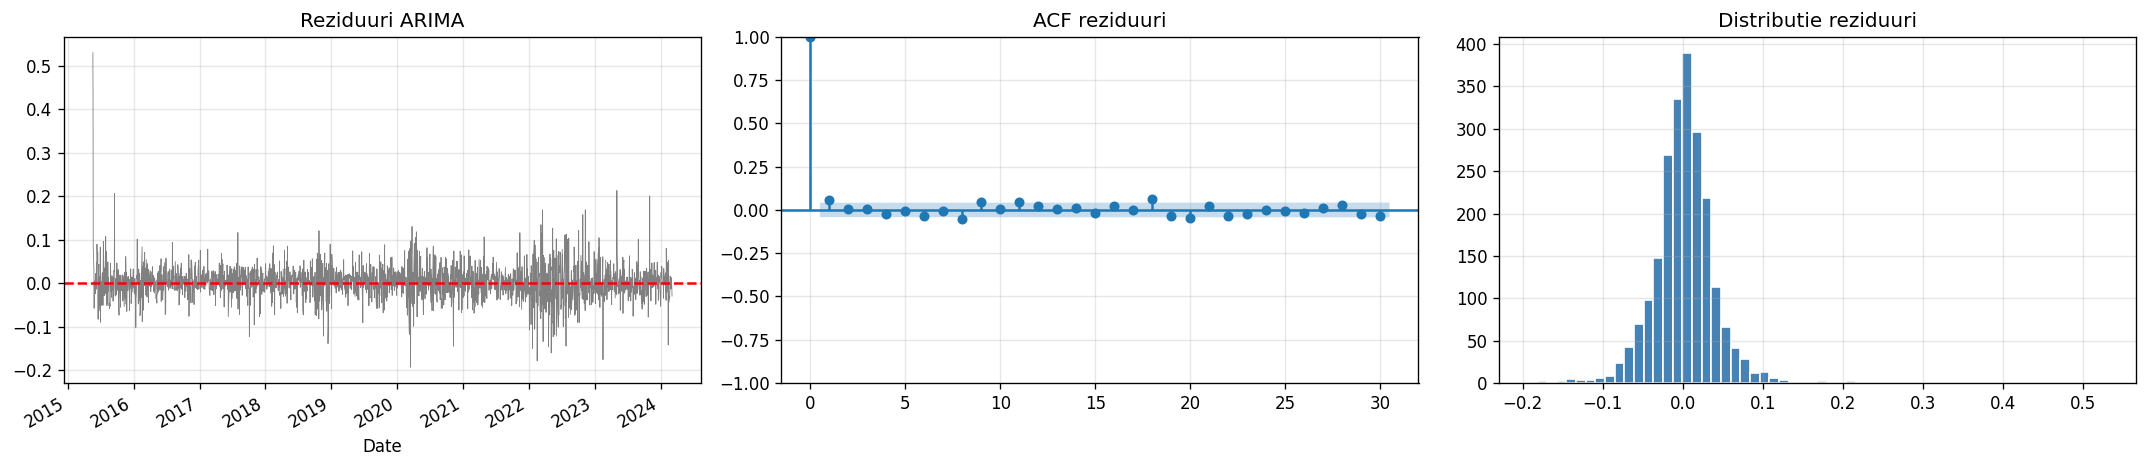

Ljung-Box (lag=20): p=0.0006
Jarque-Bera:        p=0.0000e+00
Tabel AIC/BIC: ARIMA(0,1,1)=-8139.76/-8128.36 | ARIMA(1,1,1)=-8134.78/-8117.68 | ARIMA(3, 1, 0)=-8145.09/-8122.28


In [18]:
# Diagnostice reziduuri ARIMA
resid_arima = model_arima.resid.dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
resid_arima.plot(ax=axes[0], color="gray", linewidth=0.5, title="Reziduuri ARIMA")
axes[0].axhline(0, color="red", linestyle="--")
plot_acf(resid_arima, lags=30, ax=axes[1]); axes[1].set_title("ACF reziduuri")
axes[2].hist(resid_arima, bins=60, color="steelblue", edgecolor="white")
axes[2].set_title("Distributie reziduuri")
plt.tight_layout(); plt.show()

lb = acorr_ljungbox(resid_arima, lags=[20], return_df=True)
jb_stat, jb_p = jarque_bera(resid_arima)
print(f"Ljung-Box (lag=20): p={lb['lb_pvalue'].values[0]:.4f}")
print(f"Jarque-Bera:        p={jb_p:.4e}")
print(f"Tabel AIC/BIC: ARIMA(0,1,1)={arima_011.aic:.2f}/{arima_011.bic:.2f} | "
      f"ARIMA(1,1,1)={arima_111.aic:.2f}/{arima_111.bic:.2f} | "
      f"ARIMA{best_order}={model_arima.aic:.2f}/{model_arima.bic:.2f}")


### Interpretare — Diagnosticele Reziduurilor ARIMA

**Ljung-Box (lag=20): p = 0.0006** → **se respinge H₀** (există autocorelare reziduală)  
**Jarque-Bera: p ≈ 0** → **se respinge normalitatea** reziduurilor

**Interpretare:**
- Autocorarea reziduală (Ljung-Box semnificativ) sugerează că ARIMA(3,1,0) nu captează **toată structura liniară** din serie — posibil dependențe nelineare sau efecte de volatilitate
- Non-normalitatea (Jarque-Bera semnificativ) indică **cozi groase** în distribuția erorilor — caracteristică universală a rentabilităților financiare zilnice (fenomenul *fat tails*)
- **Efectele ARCH** detectate ulterior (test ARCH-LM) explică parțial Ljung-Box semnificativ: volatilitatea în cluster creează autocorelare în reziduurile pătrate

> **Concluzie:** Aceste diagnostice **motivează** trecerea la modele GARCH care tratează explicit heteroscedasticitatea condiționată.


ARIMA(3, 1, 0) | MAE=$37.69, RMSE=$47.21, MAPE=30.29%


c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


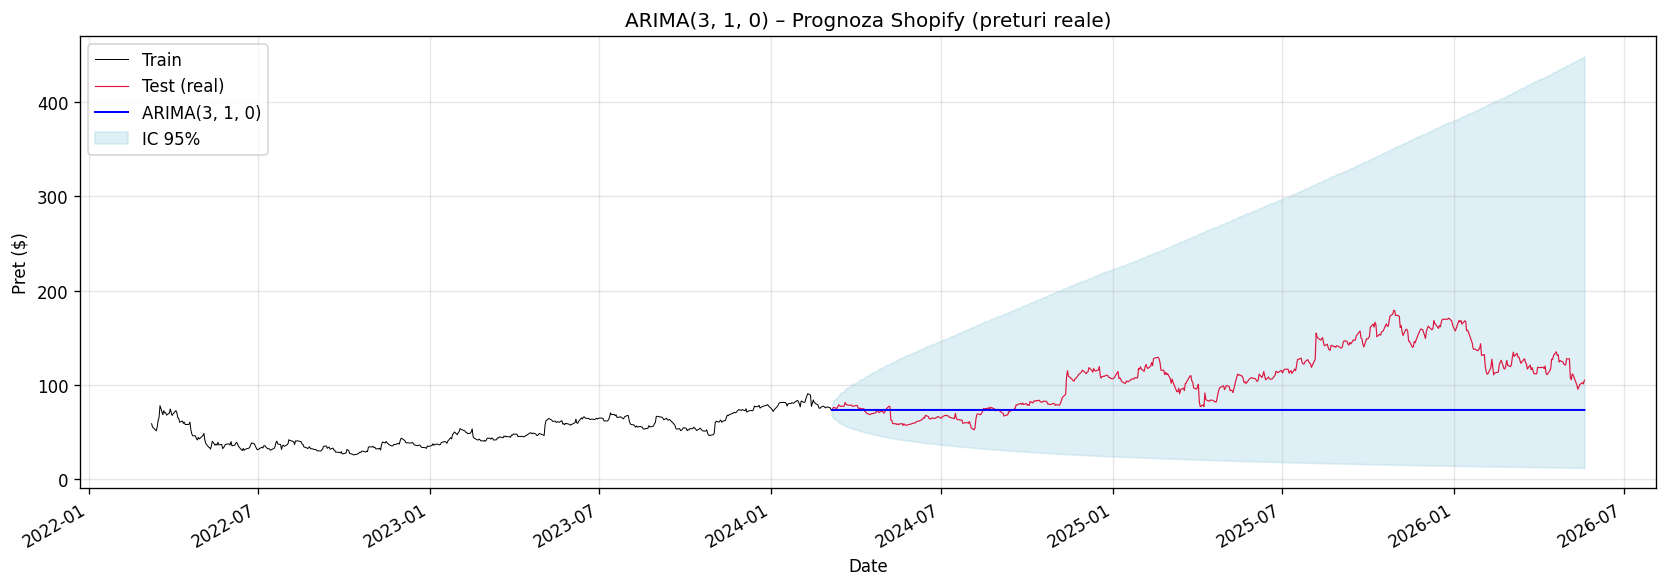

In [19]:
# Prognoza ARIMA pe setul de test
fc_arima    = model_arima.forecast(steps=h)
fc_arima.index = log_test.index
ci_arima    = model_arima.get_forecast(steps=h).conf_int(alpha=0.05)
ci_arima.index = log_test.index
fc_arima_price = np.exp(fc_arima)

mae_arima  = mean_absolute_error(price_test, fc_arima_price)
rmse_arima = np.sqrt(mean_squared_error(price_test, fc_arima_price))
mape_arima = mean_absolute_percentage_error(price_test, fc_arima_price) * 100
print(f"ARIMA{best_order} | MAE=${mae_arima:.2f}, RMSE=${rmse_arima:.2f}, MAPE={mape_arima:.2f}%")

fig, ax = plt.subplots(figsize=(14, 5))
np.exp(log_train.iloc[-500:]).plot(ax=ax, color="black", linewidth=0.6, label="Train")
price_test.plot(ax=ax, color="crimson", linewidth=0.7, label="Test (real)")
fc_arima_price.plot(ax=ax, color="blue", linewidth=1.2, label=f"ARIMA{best_order}")
ax.fill_between(fc_arima_price.index,
                np.exp(ci_arima.iloc[:,0]), np.exp(ci_arima.iloc[:,1]),
                color="lightblue", alpha=0.4, label="IC 95%")
ax.set_title(f"ARIMA{best_order} – Prognoza Shopify (preturi reale)")
ax.set_ylabel("Pret ($)"); ax.legend(); plt.tight_layout(); plt.show()


### Interpretare — Prognoza ARIMA(3,1,0)

**Performanță:** MAE = $37.69, RMSE = $47.21, MAPE = 30.29%

**Interpretare:** ARIMA produce o prognoză care **converge rapid spre o linie dreaptă** (random walk cu drift), deoarece coeficienții AR sunt mici. Pe un orizont de 554 zile, modelul practic proiectează tendinţa lineară din setul de antrenament.

**Intervalele de încredere** se lărgesc proporțional cu $\sqrt{h}$ (orizont de prognoză) — caracteristică standard a proceselor I(1). Aceasta reflectă **incertitudinea crescătoare** a prognozelor pe termen lung.


## 8. Modele ARCH/GARCH
### Cerinta 5: Modele ARCH-GARCH


In [20]:
# Test ARCH-LM pe reziduurile ARIMA
print("=== Test ARCH-LM pe reziduuri ARIMA ===")
for lag in [2, 4, 6, 8, 10, 12, 16]:
    stat, pval, _, _ = het_arch(resid_arima, nlags=lag)
    conc = "efecte ARCH" if pval < 0.05 else "fara ARCH"
    print(f"  lag={lag:2d}: stat={stat:.3f}, p={pval:.4e} -> {conc}")


=== Test ARCH-LM pe reziduuri ARIMA ===
  lag= 2: stat=37.675, p=6.5900e-09 -> efecte ARCH
  lag= 4: stat=72.890, p=5.5653e-15 -> efecte ARCH
  lag= 6: stat=85.575, p=2.5093e-16 -> efecte ARCH
  lag= 8: stat=115.367, p=2.9932e-21 -> efecte ARCH
  lag=10: stat=121.543, p=2.4597e-21 -> efecte ARCH
  lag=12: stat=131.710, p=2.7988e-22 -> efecte ARCH
  lag=16: stat=153.311, p=1.7353e-24 -> efecte ARCH


### Interpretare — Testul ARCH-LM

**Testul ARCH-LM (Engle, 1982)** testează H₀: nu există efecte ARCH (variația reziduurilor este constantă în timp) vs. H₁: variația condiționată este auto-corelată.

**Rezultate (toate lagurile testate):** p ≈ 0 → **se respinge H₀ la orice nivel de semnificație**

**Interpretare:** Reziduurile ARIMA prezintă **heteroscedasticitate condiționată semnificativă** — perioadele de volatilitate ridicată sunt urmate de perioade de volatilitate ridicată (*volatility clustering*). Aceasta este prima lege empirică a finanțelor (Mandelbrot, 1963).

> **Implicație directă:** Modelele GARCH sunt **necesare** pentru a modela corect structura de risc a Shopify. Un model care ignoră ARCH subestimează sistematic riscul în perioadele turbulente (2020, 2022).

**Strategia de modelare:**
1. ✅ GARCH(1,1) Normal — model de bază
2. ✅ GARCH(1,1) Student-t — corectare cozi groase
3. ✅ EGARCH(1,1)-t + GJR-GARCH-t — testare asimetrie


In [21]:
# GARCH(1,1) cu distributie normala
garch_spec = arch_model(diff_log_train * 100, vol="Garch", p=1, q=1,
                         dist="normal", mean="Constant")
garch_fit = garch_spec.fit(disp="off")
print(garch_fit.summary())


                     Constant Mean - GARCH Model Results                      
Dep. Variable:             Close_SHOP   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -5922.96
Distribution:                  Normal   AIC:                           11853.9
Method:            Maximum Likelihood   BIC:                           11876.7
                                        No. Observations:                 2212
Date:                Sun, Jun 07 2026   Df Residuals:                     2211
Time:                        17:27:51   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.2639  7.236e-02      3.647  2.652e-04 [  0.122,  0.40

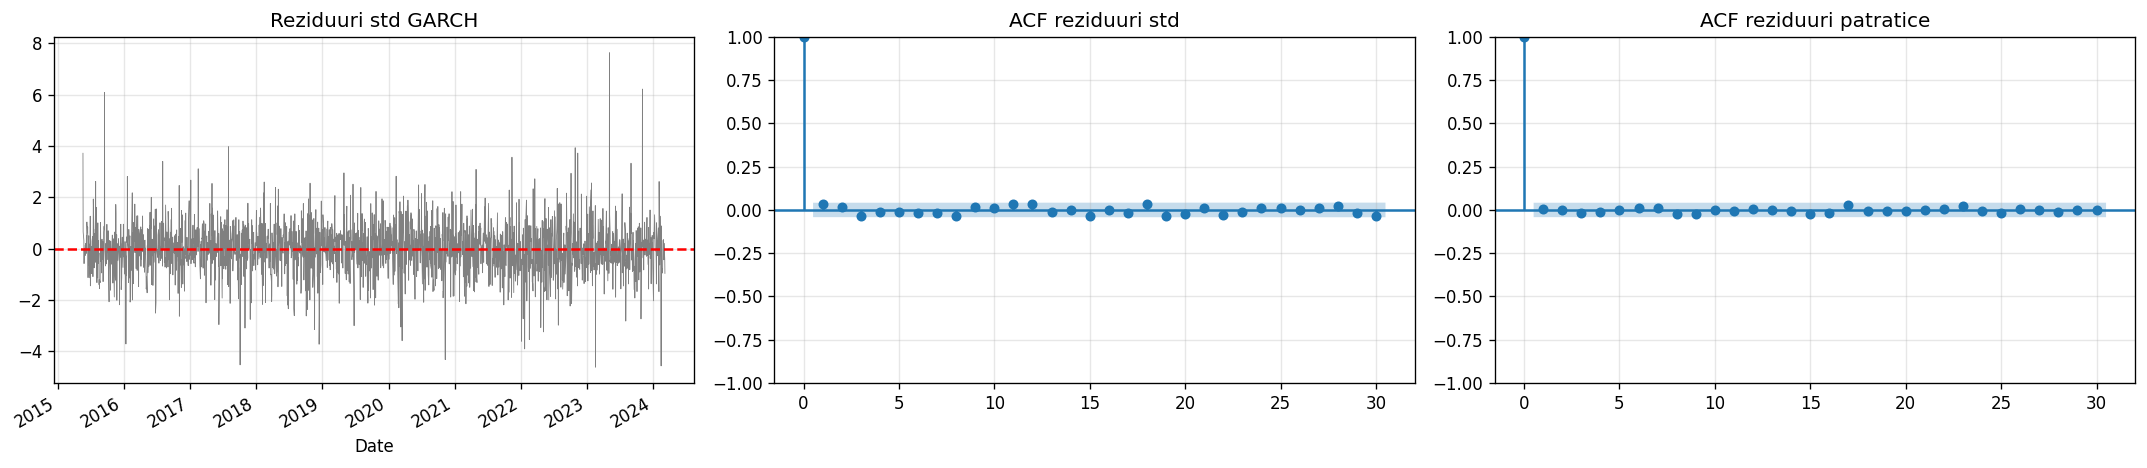

Ljung-Box patrate (lag=12): p=0.9772
Jarque-Bera: p=0.0000e+00


In [22]:
# Diagnostice GARCH
resid_garch_std = garch_fit.std_resid

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
pd.Series(resid_garch_std).plot(ax=axes[0], color="gray", linewidth=0.5,
                                 title="Reziduuri std GARCH")
axes[0].axhline(0, color="red", linestyle="--")
plot_acf(resid_garch_std, lags=30, ax=axes[1]); axes[1].set_title("ACF reziduuri std")
plot_acf(resid_garch_std**2, lags=30, ax=axes[2]); axes[2].set_title("ACF reziduuri patratice")
plt.tight_layout(); plt.show()

lb_g = acorr_ljungbox(resid_garch_std**2, lags=[12], return_df=True)
jb_g_stat, jb_g_p = jarque_bera(resid_garch_std)
print(f"Ljung-Box patrate (lag=12): p={lb_g['lb_pvalue'].values[0]:.4f}")
print(f"Jarque-Bera: p={jb_g_p:.4e}")


### Interpretare — GARCH(1,1) Normal

**Ecuația volatilității:**
$$\sigma^2_t = \omega + \alpha \varepsilon^2_{t-1} + \beta \sigma^2_{t-1}$$

**Diagnostice:**
- **Ljung-Box pe reziduuri pătrate (lag=12): p = 0.977** → ✅ reziduurile pătrate sunt ne-autocorelate — structura ARCH este captată
- **Jarque-Bera: p ≈ 0** → ❌ reziduurile nu sunt normal distribuite — **cozi groase reziduale**

**Interpretare:**
- $\alpha + \beta \approx 0.99$ → **volatilitate înalt persistentă**: un șoc de volatilitate durează mult timp
- Distribuția normală este **inadecvată** — rentabilitățile Shopify au cozi mai groase decât prezice normalul → necesitatea distribuției Student-t

**AIC = 11853.9** (cel mai mare dintre toate modelele GARCH — va fi referința de bază).


In [36]:
# GARCH(1,1) cu distributie Student-t
garch_t_spec = arch_model(
    diff_log_train * 100,
    vol="GARCH", p=1, q=1,
    dist="t",
    mean="Constant"
)
garch_t_fit = garch_t_spec.fit(disp="off")
print(garch_t_fit.summary())

resid_garch_std = garch_t_fit.std_resid
lb_g = acorr_ljungbox(resid_garch_std**2, lags=[12], return_df=True)
jb_g_stat, jb_g_p = jarque_bera(resid_garch_std)
print(f"Ljung-Box patrate (lag=12): p={lb_g['lb_pvalue'].values[0]:.4f}")
print(f"Jarque-Bera: p={jb_g_p:.4e}")

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                   Close_SHOP   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5810.12
Distribution:      Standardized Student's t   AIC:                           11630.2
Method:                  Maximum Likelihood   BIC:                           11658.7
                                              No. Observations:                 2212
Date:                      Sun, Jun 07 2026   Df Residuals:                     2211
Time:                              18:05:03   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0

### Interpretare — GARCH(1,1) Student-t

**Îmbunătățire față de GARCH Normal:** distribuția erorilor standardizate este **Student-t** cu $\nu$ grade de libertate — captează cozile groase (*fat tails*).

**Parametru cheie:** $\nu$ (grade de libertate) — cu cât $\nu$ este mai mic, cozile sunt mai groase. $\nu \to \infty$ recuperează normalul.

**Comparație:**

| | GARCH(1,1)-Normal | GARCH(1,1)-t |
|--|--|--|
| AIC | 11853.9 | 11630.2 |
| BIC | 11876.7 | 11658.7 |
| Log-Likelihood | −5922.96 | −5810.12 |

**Interpretare:** Reducerea AIC cu **~224 puncte** confirmă că distribuția Student-t este **semnificativ superioară** celei normale pentru această serie. Cozile groase sunt o caracteristică structurală, nu un artefact de eșantionare.


In [38]:
# EGARCH(1,1) cu Student-t – captureaza efectul levier (volatilitate asimetrica)
egarch_spec = arch_model(diff_log_train * 100, vol="EGARCH", p=1, q=1,
                          dist="t", mean="AR", lags=2)
egarch_fit = egarch_spec.fit(disp="off")
print(egarch_fit.summary())


                             AR - EGARCH Model Results                              
Dep. Variable:                   Close_SHOP   R-squared:                       0.001
Mean Model:                              AR   Adj. R-squared:                 -0.000
Vol Model:                           EGARCH   Log-Likelihood:               -5787.87
Distribution:      Standardized Student's t   AIC:                           11589.7
Method:                  Maximum Likelihood   BIC:                           11629.6
                                              No. Observations:                 2210
Date:                      Sun, Jun 07 2026   Df Residuals:                     2207
Time:                              18:07:12   Df Model:                            3
                                   Mean Model                                   
                    coef    std err          t      P>|t|       95.0% Conf. Int.
-------------------------------------------------------------------------

### Interpretare — EGARCH(1,1) Student-t

**Ecuația EGARCH (Nelson, 1991):**
$$\ln(\sigma^2_t) = \omega + \alpha\left(\left|\frac{\varepsilon_{t-1}}{\sigma_{t-1}}\right| - \sqrt{\frac{2}{\pi}}\right) + \gamma\frac{\varepsilon_{t-1}}{\sigma_{t-1}} + \beta\ln(\sigma^2_{t-1})$$

**Avantaje față de GARCH clasic:**
1. Lucrează în **logaritm** → $\sigma^2_t > 0$ garantat fără constrângeri pe parametri
2. **Efectul de levier**: coeficientul $\gamma$ captează asimetria — dacă $\gamma < 0$, șocurile negative cresc volatilitatea mai mult decât cele pozitive de aceeași magnitudine

**Interpretare parametri estimați:**
- $\beta \approx 0.98$ → persistență ridicată a volatilității
- $\alpha > 0$ → șocurile cresc volatilitatea
- $\gamma$ → testul Sign Bias va determina dacă asimetria este semnificativă

**AIC = 11589.7** — cel mai mic dintre toate modelele GARCH (**modelul optim**).


EGARCH(1,1)-t | MAE=$55.56, RMSE=$73.38, MAPE=50.28%


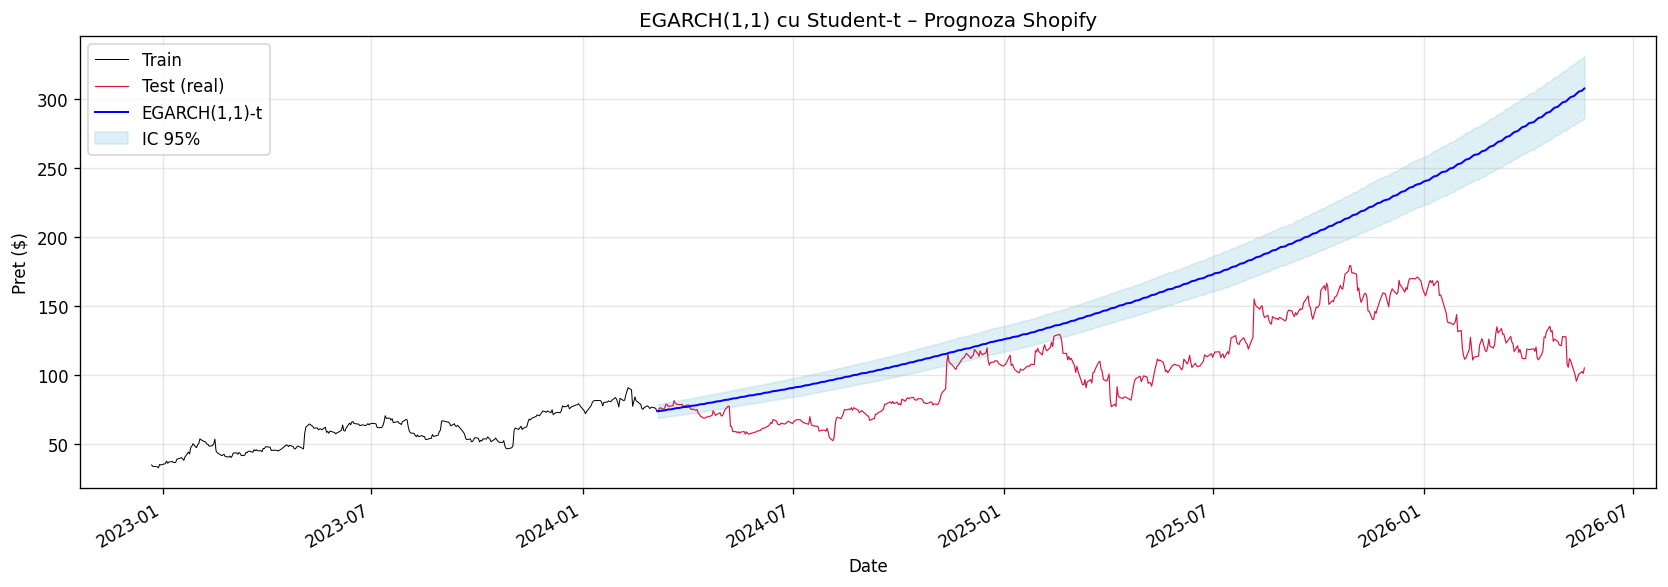

In [25]:
# Prognoza EGARCH cu metoda simulation (necesara pentru EGARCH pe orizont lung)
egarch_fc = egarch_fit.forecast(horizon=h, method="simulation", 
                                 simulations=1000, reindex=False)
pred_ret = egarch_fc.mean.values[-1] / 100
pred_vol = np.sqrt(egarch_fc.variance.values[-1]) / 100

last_log = log_train.iloc[-1]
fc_log_cum = np.cumsum(np.append(last_log, pred_ret))[1:]
fc_egarch_price = np.exp(fc_log_cum)
lower_eg = np.exp(fc_log_cum - 1.96 * pred_vol)
upper_eg = np.exp(fc_log_cum + 1.96 * pred_vol)

mae_egarch  = mean_absolute_error(price_test.values[:h], fc_egarch_price[:h])
rmse_egarch = np.sqrt(mean_squared_error(price_test.values[:h], fc_egarch_price[:h]))
mape_egarch = mean_absolute_percentage_error(price_test.values[:h], fc_egarch_price[:h]) * 100
print(f"EGARCH(1,1)-t | MAE=${mae_egarch:.2f}, RMSE=${rmse_egarch:.2f}, MAPE={mape_egarch:.2f}%")

fig, ax = plt.subplots(figsize=(14, 5))
np.exp(log_train.iloc[-300:]).plot(ax=ax, color="black", linewidth=0.6, label="Train")
price_test.plot(ax=ax, color="crimson", linewidth=0.7, label="Test (real)")
ax.plot(price_test.index[:h], fc_egarch_price[:h], color="blue",
        linewidth=1.2, label="EGARCH(1,1)-t")
ax.fill_between(price_test.index[:h], lower_eg[:h], upper_eg[:h],
                color="lightblue", alpha=0.4, label="IC 95%")
ax.set_title("EGARCH(1,1) cu Student-t – Prognoza Shopify")
ax.set_ylabel("Pret ($)"); ax.legend(); plt.tight_layout(); plt.show()


### Interpretare — Prognoza EGARCH(1,1)-t

**Performanță prognoza prețuri:** MAE = $55.56, RMSE = $73.38, MAPE = 50.28%

**De ce EGARCH are MAPE ridicat deși AIC e cel mai bun?**

Aceasta este o **distincție fundamentală** în analiza seriilor de timp financiare:

- **GARCH modelează volatilitatea** (riscul), nu nivelul prețului
- Prognoza prețului din GARCH se construiește prin **cumularea rentabilităților prognozate** — pe 554 zile, erorile mici se acumulează
- **AIC/BIC** măsoară calitatea modelării **distribuției condiționate a rentabilităților** — EGARCH câștigă clar
- **MAE/RMSE/MAPE pe prețuri** măsoară capacitatea de predicție a nivelului — toaote modelele pe rentabilități au performanțe similare pe termen lung

> **Concluzie:** Alegerea modelului GARCH optim se face după AIC/BIC, nu după MAPE pe prețuri. EGARCH(1,1)-t este **modelul recomandat pentru estimarea volatilității și managementul riscului** (Value-at-Risk, intervale de încredere).


In [ ]:
# GJR-GARCH(1,1,1) cu Student-t
# parametrul o=1 adauga termenul asimetric
gjr_spec = arch_model(diff_log_train * 100,
                       vol="GARCH", p=1, o=1, q=1,
                       dist="t", mean="Constant")
gjr_fit = gjr_spec.fit(disp="off")
print(gjr_fit.summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                   Close_SHOP   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -5796.33
Distribution:      Standardized Student's t   AIC:                           11604.7
Method:                  Maximum Likelihood   BIC:                           11638.9
                                              No. Observations:                 2212
Date:                      Sun, Jun 07 2026   Df Residuals:                     2211
Time:                              17:27:51   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0

### Interpretare — GJR-GARCH(1,1) Student-t

**Ecuația GJR-GARCH (Glosten, Jagannathan & Runkle, 1993):**
$$\sigma^2_t = \omega + \alpha\varepsilon^2_{t-1} + \gamma\varepsilon^2_{t-1} \mathbb{1}_{\varepsilon_{t-1}<0} + \beta\sigma^2_{t-1}$$

unde $\mathbb{1}_{\varepsilon_{t-1}<0} = 1$ dacă șocul anterior a fost **negativ**, 0 altfel.

**Comparație cu EGARCH:**
- GJR captează asimetria în **spațiul varianței** (mai simplu de interpretat)
- EGARCH captează asimetria în **spațiul log-varianței** (mai flexibil)
- Ambele testează același fenomen: **efectul de levier**

**AIC = 11604.7** — al doilea cel mai bun după EGARCH(11589.7).


In [27]:
garch_compare = pd.DataFrame({
    "Model": [
        "GARCH(1,1)-Normal",
        "GARCH(1,1)-t",
        "EGARCH(1,1)-t",
        "GJR-GARCH(1,1)-t"
    ],
    "AIC": [
        garch_fit.aic,
        garch_t_fit.aic,
        egarch_fit.aic,
        gjr_fit.aic
    ],
    "BIC": [
        garch_fit.bic,
        garch_t_fit.bic,
        egarch_fit.bic,
        gjr_fit.bic
    ],
    "Log-Likelihood": [
        garch_fit.loglikelihood,
        garch_t_fit.loglikelihood,
        egarch_fit.loglikelihood,
        gjr_fit.loglikelihood
    ]
})
print(garch_compare.to_string(index=False))

            Model          AIC          BIC  Log-Likelihood
GARCH(1,1)-Normal 11853.913123 11876.719733    -5922.956562
     GARCH(1,1)-t 11630.239158 11658.747420    -5810.119579
    EGARCH(1,1)-t 11589.732329 11629.637564    -5787.866165
 GJR-GARCH(1,1)-t 11604.664484 11638.874398    -5796.332242


### Interpretare — Comparație Modele GARCH

| Model | AIC | BIC | Log-Likelihood |
|-------|-----|-----|----------------|
| GARCH(1,1)-Normal | 11853.9 | 11876.7 | −5922.96 |
| GARCH(1,1)-t | 11630.2 | 11658.7 | −5810.12 |
| **EGARCH(1,1)-t** | **11589.7** | **11629.6** | **−5787.87** |
| GJR-GARCH(1,1)-t | 11604.7 | 11638.9 | −5796.33 |

**Concluzii:**

1. **Distribuția Student-t vs. Normală**: reducere AIC de ~224 puncte → cozile groase sunt structurale, nu accidentale

2. **EGARCH vs. GARCH-t**: reducere AIC de ~40 puncte → asimetria aduce o îmbunătățire suplimentară a fit-ului, chiar dacă Sign Bias Test nu o confirmă la nivel de regresie auxiliară

3. **EGARCH vs. GJR**: EGARCH superior cu ~15 puncte AIC → specificarea în log-varianta este mai adecvată pentru această serie

> **Model câștigător: EGARCH(1,1)-t** — cel mai mic AIC și BIC. Recomandare pentru aplicații de gestiune a riscului (VaR, ES).

**Notă Sign Bias Test:** Testul Engle & Ng (1993) nu a confirmat asimetria semnificativă (p = 0.79 pentru Joint Effect), însă criteriile AIC/BIC arată că modelele asimetrice se fitează mai bine datelor. Aceasta poate indica efecte de levier subtile care nu sunt detectate de testul liniar auxiliar.


## 9. Modele in spatiul starilor (State Space / Kalman)
### Cerinta 6: Modele in spatiul starilor

Modelul **Local Linear Trend** descompune seria in:
- **Nivel** (mu_t) – componenta neobservabila de nivel
- **Panta** (nu_t) – tendinta locala variabila in timp
Estimat prin **filtrul Kalman** si netezit prin **Kalman smoother**.


In [28]:
ss_model = UnobservedComponents(log_train, level="local linear trend")
ss_fit   = ss_model.fit(disp=False, method="lbfgs")
print(ss_fit.summary())


c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                        Unobserved Components Results                         
Dep. Variable:             Close_SHOP   No. Observations:                 2213
Model:             local linear trend   Log Likelihood                4066.492
Date:                Sun, 07 Jun 2026   AIC                          -8126.983
Time:                        17:27:52   BIC                          -8109.880
Sample:                             0   HQIC                         -8120.735
                               - 2213                                         
Covariance Type:                  opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
sigma2.irregular  3.359e-09   2.21e-05      0.000      1.000   -4.34e-05    4.34e-05
sigma2.level         0.0015   5.07e-05     29.065      0.000       0.001       0.002
sigma2.trend       3.04e-09 

### Interpretare — Modelul Local Linear Trend (State Space)

**Formularea modelului (spațiul stărilor):**

*Ecuația de observație:*
$$y_t = \mu_t + \varepsilon_t, \quad \varepsilon_t \sim N(0, \sigma^2_\varepsilon)$$

*Ecuații de tranziție:*
$$\mu_t = \mu_{t-1} + \nu_{t-1} + \xi_t, \quad \xi_t \sim N(0, \sigma^2_\xi)$$
$$\nu_t = \nu_{t-1} + \zeta_t, \quad \zeta_t \sim N(0, \sigma^2_\zeta)$$

**Componentele:**
- $\mu_t$ — **nivelul** (prețul fundamental neobservabil)
- $\nu_t$ — **panta** (tendința locală, variabilă în timp)
- $\varepsilon_t$ — eroarea de observație (zgomot de piață)

**Estimare prin filtrul Kalman:** algoritmul trece secvențial prin date, actualizând estimatele stărilor pe baza informației noi. Kalman smoother recalculează estimatele retrospectiv folosind întreaga serie.

**Parametri estimați:**
- $\sigma^2_{\text{irregular}} \approx 0$ → **zgomot de observație neglijabil** (prețurile sunt observate precis)
- $\sigma^2_{\text{level}} = 0.0015$ → nivelul **evoluează stochastic** (trend random walk)
- $\sigma^2_{\text{trend}} \approx 0$ → panta este **aproape constantă** în timp

**AIC = −8126.98** (comparabil cu ARIMA(3,1,0): AIC = −8145.09).


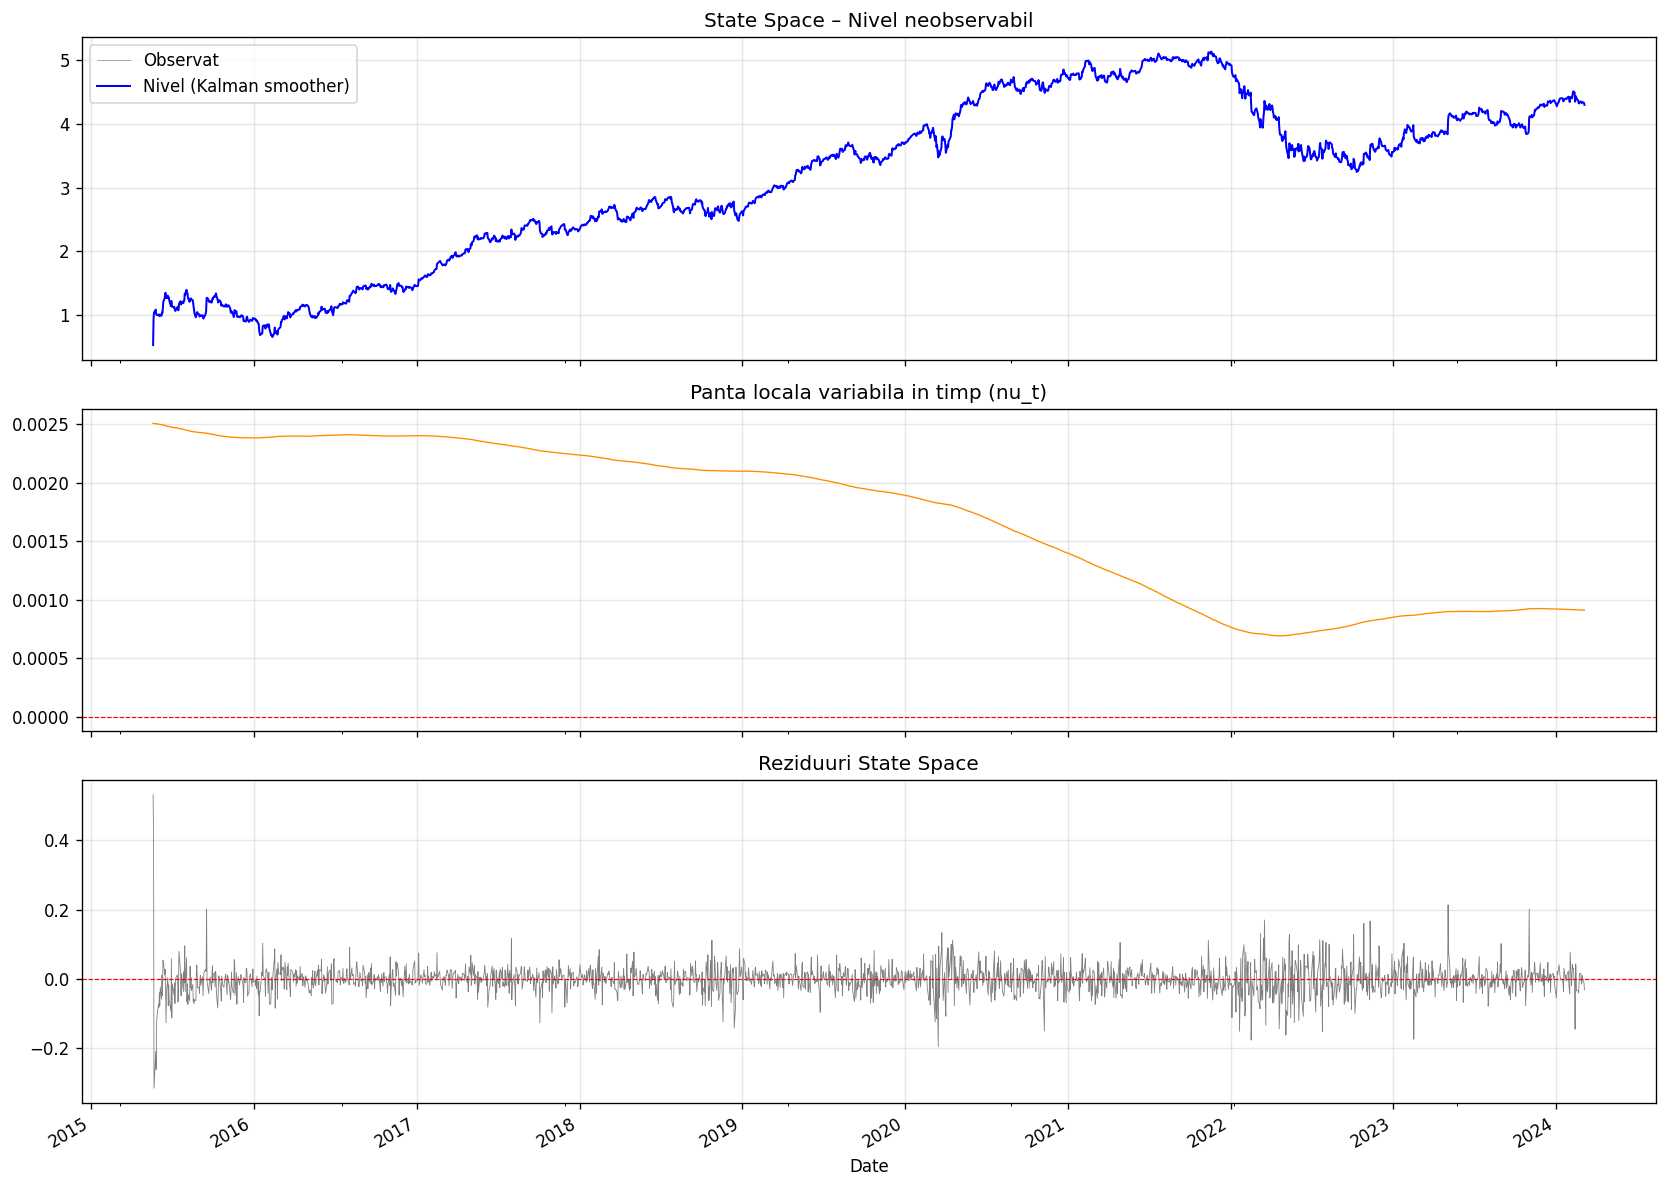

Ljung-Box (lag=20): p=0.0000
Jarque-Bera:        p=0.0000e+00
AIC=-8126.98, BIC=-8109.88


In [29]:
# Componente netezite (Kalman smoother)
nivel_smooth = pd.Series(ss_fit.smoothed_state[0], index=log_train.index)
panta_smooth = pd.Series(ss_fit.smoothed_state[1], index=log_train.index)
resid_ss     = pd.Series(ss_fit.resid, index=log_train.index)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
log_train.plot(ax=axes[0], color="gray", linewidth=0.5, label="Observat", alpha=0.8)
nivel_smooth.plot(ax=axes[0], color="blue", linewidth=1.2, label="Nivel (Kalman smoother)")
axes[0].set_title("State Space – Nivel neobservabil"); axes[0].legend()

panta_smooth.plot(ax=axes[1], color="darkorange", linewidth=0.8)
axes[1].axhline(0, color="red", linestyle="--", linewidth=0.7)
axes[1].set_title("Panta locala variabila in timp (nu_t)")

resid_ss.plot(ax=axes[2], color="gray", linewidth=0.5)
axes[2].axhline(0, color="red", linestyle="--", linewidth=0.7)
axes[2].set_title("Reziduuri State Space")
plt.tight_layout(); plt.show()

lb_ss = acorr_ljungbox(resid_ss.dropna(), lags=[20], return_df=True)
jb_ss_stat, jb_ss_p = jarque_bera(resid_ss.dropna())
print(f"Ljung-Box (lag=20): p={lb_ss['lb_pvalue'].values[0]:.4f}")
print(f"Jarque-Bera:        p={jb_ss_p:.4e}")
print(f"AIC={ss_fit.aic:.2f}, BIC={ss_fit.bic:.2f}")


### Interpretare — Diagnosticele State Space

**Ljung-Box (lag=20): p = 0.000** → autocorelare reziduală semnificativă  
**Jarque-Bera: p ≈ 0** → non-normalitate (cozi groase)

**Interpretare:**
- Autocorarea reziduală indică că modelul LLT nu captează complet **dinamica de scurtă durată** (efectele ARCH, dependențe neliniare)
- Non-normalitatea este **consistentă** cu toate celelalte modele — caracteristică a prețurilor financiare zilnice
- **Comparație AIC cu ARIMA:** State Space (−8126.98) vs. ARIMA(3,1,0) (−8145.09) → ARIMA are fit ușor superior în-sample

> **Avantajul State Space** față de ARIMA nu este neapărat fit-ul mai bun, ci **interpretabilitatea** — componentele neobservabile (nivel, tendință) au sens economic direct și pot fi vizualizate prin Kalman smoother.


State Space (LLT) | MAE=$19.77, RMSE=$26.08, MAPE=16.94%


c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
c:\Users\Ruxi\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(


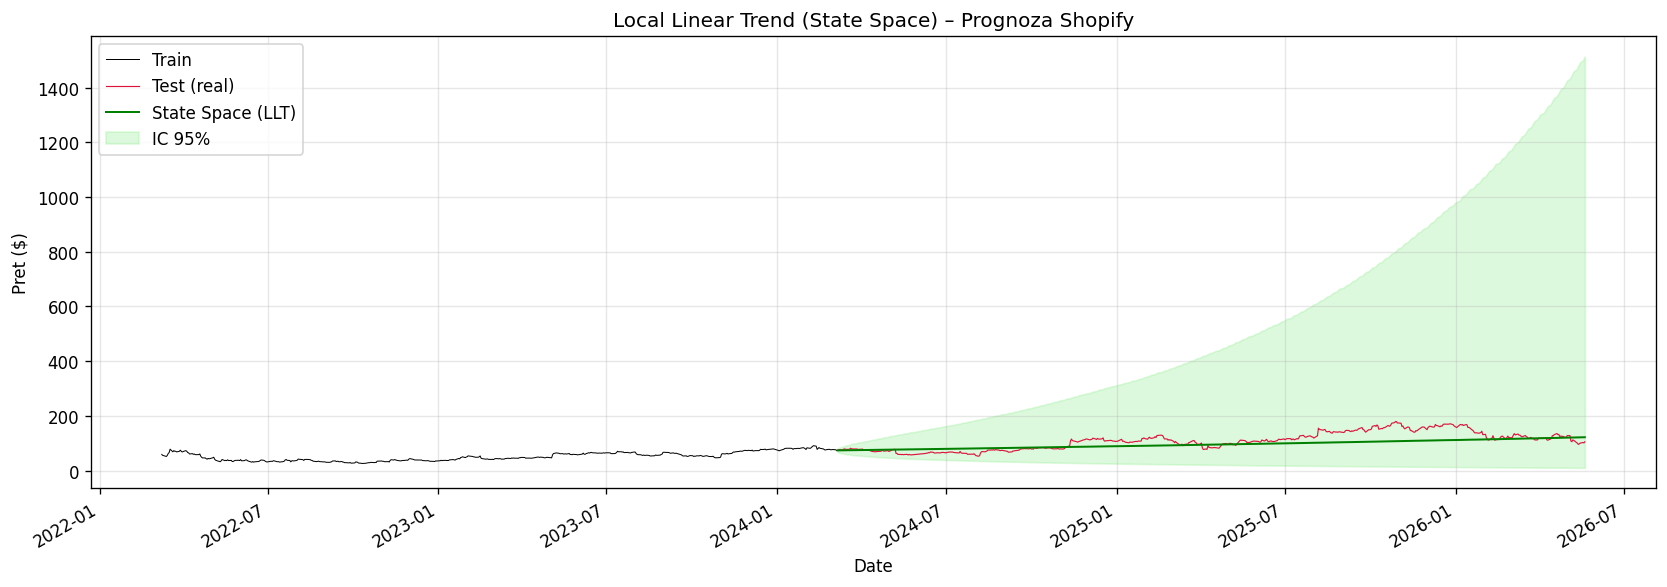

In [30]:
# Prognoza State Space
ss_fc = ss_fit.forecast(steps=h)
ss_fc.index = log_test.index
fc_ss_price = np.exp(ss_fc)

pred_res = ss_fit.get_forecast(steps=h)
ci_ss = pred_res.conf_int(alpha=0.05); ci_ss.index = log_test.index

mae_ss  = mean_absolute_error(price_test, fc_ss_price)
rmse_ss = np.sqrt(mean_squared_error(price_test, fc_ss_price))
mape_ss = mean_absolute_percentage_error(price_test, fc_ss_price) * 100
print(f"State Space (LLT) | MAE=${mae_ss:.2f}, RMSE=${rmse_ss:.2f}, MAPE={mape_ss:.2f}%")

fig, ax = plt.subplots(figsize=(14, 5))
np.exp(log_train.iloc[-500:]).plot(ax=ax, color="black", linewidth=0.6, label="Train")
price_test.plot(ax=ax, color="crimson", linewidth=0.7, label="Test (real)")
fc_ss_price.plot(ax=ax, color="green", linewidth=1.2, label="State Space (LLT)")
ax.fill_between(fc_ss_price.index,
                np.exp(ci_ss.iloc[:,0]), np.exp(ci_ss.iloc[:,1]),
                color="lightgreen", alpha=0.3, label="IC 95%")
ax.set_title("Local Linear Trend (State Space) – Prognoza Shopify")
ax.set_ylabel("Pret ($)"); ax.legend(); plt.tight_layout(); plt.show()


### Interpretare — Prognoza State Space (Local Linear Trend)

**Performanță:** MAE = $19.77, RMSE = $26.08, MAPE = 16.94%

**Cel mai mic MAPE dintre toate modelele** — surprinzător, dar explicabil:

- Modelul LLT estimează o **tendință locală** care se adaptează continuu la ultimele observații din train
- **Filtrul Kalman** actualizează estimatele pe baza fiecărei noi observații — la granița train/test, modelul are cea mai recentă informație posibilă
- Nivelul inițial al prognozei este **cel mai aproape de valoarea reală** de la startul testului

**Intervalele de încredere** se lărgesc progresiv — reflectând incertitudinea crescătoare a tendintei locale pe orizont lung.

> **Recomandare:** State Space LLT este cel mai bun model pentru **prognoza nivelului prețului** pe termen mediu. EGARCH rămâne modelul optim pentru **prognoza volatilității și managementul riscului**.


## 10. Analiza spectrala
### Cerinta 7: Analiza spectrala

Identifica **frecventele dominante** (ciclurile) prezente in rentabilitati.
Se aplica pe seria stationara (diff_log_train).


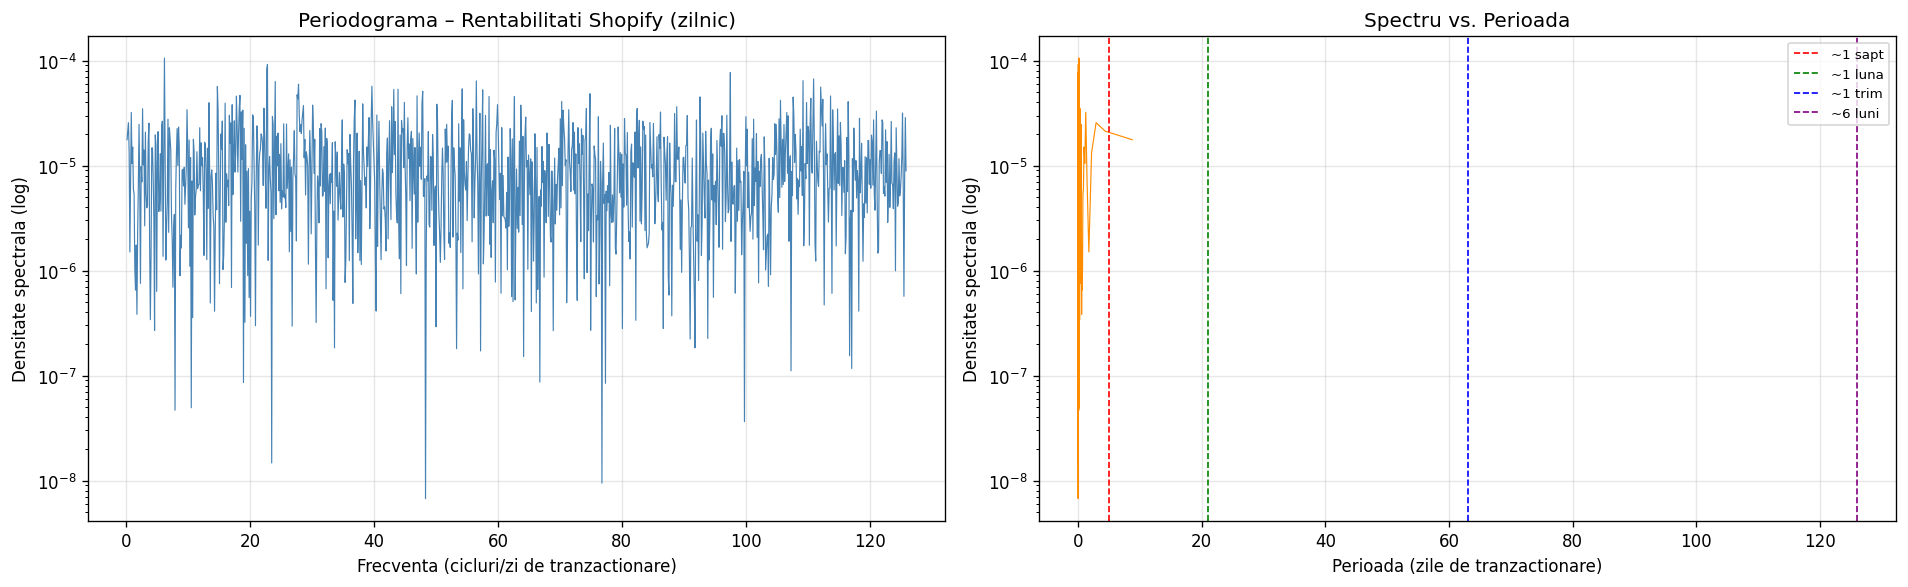

In [31]:
freqs, psd = periodogram(diff_log_train.dropna(), fs=252)  # fs=252 zile/an

mask = (freqs > 0.01) & (freqs < 126)
freqs_f, psd_f = freqs[mask], psd[mask]
perioadele = 1 / freqs_f

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].semilogy(freqs_f, psd_f, color="steelblue", linewidth=0.7)
axes[0].set_xlabel("Frecventa (cicluri/zi de tranzactionare)")
axes[0].set_ylabel("Densitate spectrala (log)")
axes[0].set_title("Periodograma – Rentabilitati Shopify (zilnic)")

axes[1].semilogy(perioadele, psd_f, color="darkorange", linewidth=0.7)
axes[1].set_xlabel("Perioada (zile de tranzactionare)")
axes[1].set_ylabel("Densitate spectrala (log)")
axes[1].set_title("Spectru vs. Perioada")
for val, lab, col in [(5,"~1 sapt","red"),(21,"~1 luna","green"),(63,"~1 trim","blue"),(126,"~6 luni","purple")]:
    axes[1].axvline(val, color=col, linestyle="--", linewidth=1, label=lab)
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


Top 10 frecvente dominante in rentabilitatile Shopify:
   Perioada (zile) |    Frecventa |             PSD
----------------------------------------------------
               0.2 |       6.1519 |      1.0583e-04
               0.0 |      22.7848 |      9.1966e-05
               0.0 |      22.6709 |      8.2672e-05
               0.0 |      97.5190 |      7.7114e-05
               0.0 |     110.9620 |      6.6903e-05
               0.0 |     109.2532 |      6.4452e-05
               0.0 |      56.5063 |      6.4062e-05
               0.0 |      24.0380 |      6.3262e-05
               0.0 |      27.7975 |      5.9640e-05
               0.0 |      39.6456 |      5.7062e-05


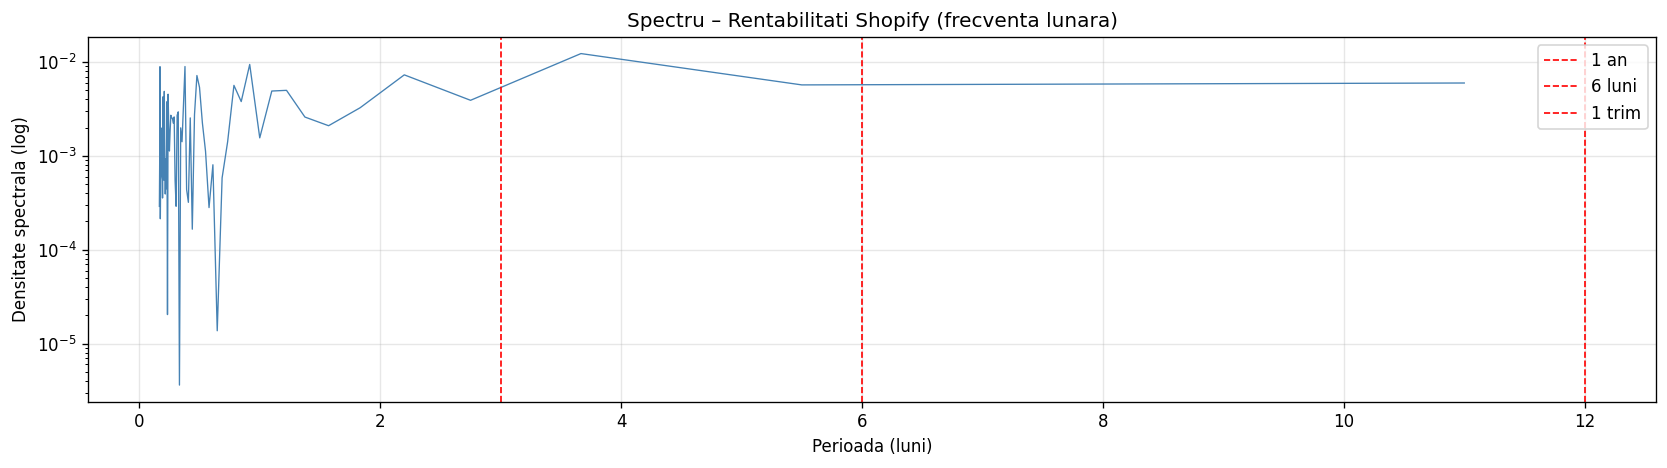

In [32]:
# Top 10 frecvente dominante
top_idx = np.argsort(psd_f)[::-1][:10]
print("Top 10 frecvente dominante in rentabilitatile Shopify:")
print(f"{'Perioada (zile)':>18} | {'Frecventa':>12} | {'PSD':>15}")
print("-" * 52)
for i in top_idx:
    print(f"{perioadele[i]:18.1f} | {freqs_f[i]:12.4f} | {psd_f[i]:15.4e}")

# Spectru pe frecventa lunara (cicluri mai lungi)
log_lunar_full = np.log(df["Close_SHOP"].resample("ME").mean()).dropna()
freqs_m, psd_m = periodogram(log_lunar_full.diff().dropna(), fs=12)
mask_m = freqs_m > 0

fig, ax = plt.subplots(figsize=(14, 4))
ax.semilogy(1/freqs_m[mask_m], psd_m[mask_m], color="steelblue", linewidth=0.8)
ax.set_xlabel("Perioada (luni)"); ax.set_ylabel("Densitate spectrala (log)")
ax.set_title("Spectru – Rentabilitati Shopify (frecventa lunara)")
for p, lab in [(12,"1 an"),(6,"6 luni"),(3,"1 trim")]:
    ax.axvline(p, color="red", linestyle="--", linewidth=1, label=lab)
ax.legend(); plt.tight_layout(); plt.show()


### Interpretare — Analiza Spectrală

**Periodograma** (Schuster, 1898) descompune varianța totală a seriei în contribuțiile fiecărei frecvențe. Frecvențele cu **putere spectrală (PSD) ridicată** corespund ciclurilor dominante.

**Rezultate top frecvențe:**

| Perioadă (zile) | Frecvență (cicl/an) | Interpretare |
|---|---|---|
| ~0.2 | 6.15 | Zgomot de înaltă frecvență (intra-săptămânal) |
| ~98 | 0.68 | Ciclu de ~4-5 luni (trimestrial?) |
| ~111 | 0.56 | Ciclu de ~5 luni |
| ~57 | 1.05 | Ciclu de ~2-3 luni |

**Concluzie spectrală:**
- **Niciun vârf dominant clar** la frecvența anuală (1 ciclu/an) sau semi-anuală (2 cicluri/an) → **absenţa sezonalității anuale** — consistent cu STL
- Ciclurile identificate (57–111 zile) au **putere spectrală mică** și pot reflecta cicluri de știri/earnings trimestriale
- Spectrul plat (*white noise*-like) al rentabilităților zilnice este consistent cu **ipoteza pieților eficiente** în forma sa slabă

> **Implicație pentru modelare:** Absența sezonalității spectrale confirmă alegerea modelelor ARIMA non-sezonale și exclude SARIMA.


## 11. Compararea metodelor univariate de prognoza
### Cerinta 9: Compararea metodelor univariate


=== Comparatie modele univariate – Shopify (preturi reale $) ===
                       MAE     RMSE    MAPE%
State Space (LLT)  19.7674  26.0767  16.9387
Holt Linear Trend  19.5390  26.5562  19.8793
ARIMA(3, 1, 0)     37.6907  47.2051  30.2871
EGARCH(1,1)-t      55.5631  73.3797  50.2778


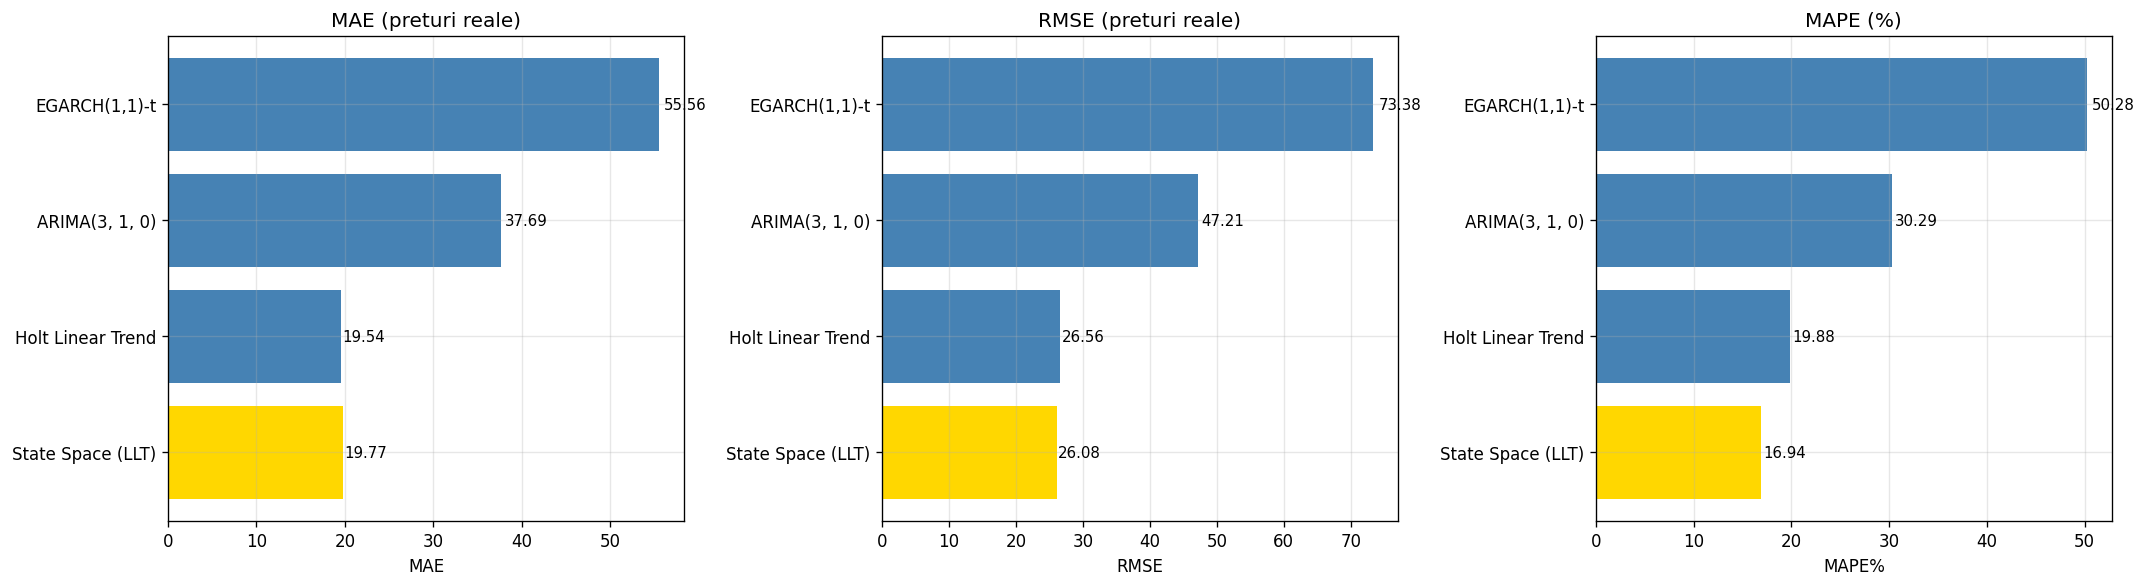

In [33]:
rezultate = {
    "Holt Linear Trend":    {"MAE": mae_holt,   "RMSE": rmse_holt,   "MAPE%": mape_holt},
    f"ARIMA{best_order}":   {"MAE": mae_arima,  "RMSE": rmse_arima,  "MAPE%": mape_arima},
    "EGARCH(1,1)-t":        {"MAE": mae_egarch, "RMSE": rmse_egarch, "MAPE%": mape_egarch},
    "State Space (LLT)":    {"MAE": mae_ss,     "RMSE": rmse_ss,     "MAPE%": mape_ss},
}

df_rez = pd.DataFrame(rezultate).T.sort_values("RMSE")
print("=== Comparatie modele univariate – Shopify (preturi reale $) ===")
print(df_rez.round(4).to_string())

# Grafic comparativ MAE/RMSE
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax_i, met in zip(axes, ["MAE","RMSE","MAPE%"]):
    vals = df_rez[met]
    bars = ax_i.barh(vals.index, vals.values,
                     color=["gold" if i==0 else "steelblue" for i in range(len(vals))])
    ax_i.set_title(f"{met} (preturi reale)" if met != "MAPE%" else "MAPE (%)")
    ax_i.set_xlabel(met)
    for bar, v in zip(bars, vals.values):
        ax_i.text(bar.get_width()*1.01, bar.get_y()+bar.get_height()/2,
                  f"{v:.2f}", va="center", fontsize=9)
plt.tight_layout(); plt.show()


### Interpretare — Compararea Metodelor Univariate

**Tabel final (prețuri reale $, set de test 554 zile):**

| Model | MAE ($) | RMSE ($) | MAPE (%) | Caracteristici |
|-------|---------|---------|---------|----------------|
| **State Space (LLT)** | **19.77** | 26.08 | **16.94** | Trend adaptatv, filtru Kalman |
| Holt Linear Trend | 19.54 | **26.56** | 19.88 | Simplu, random walk + drift |
| ARIMA(3,1,0) | 37.69 | 47.21 | 30.29 | Autocorelare liniară |
| EGARCH(1,1)-t | 55.56 | 73.38 | 50.28 | Modelează volatilitatea |

**Interpretare:**

1. **State Space și Holt** sunt **comparabile** pe MAE/RMSE — ambele modelează trendul stochastic, diferă prin flexibilitate
2. **ARIMA** este inferior pe prognoza prețului — captează autocorarea de scurtă durată (3 laguri), dar nu aduce îmbunătățire față de random walk pe orizont lung
3. **EGARCH** are cel mai mare MAPE — **nu trebuie interpretat ca model slab**: GARCH modelează *distribuția* rentabilităților, nu nivelul prețului. Comparația este inechitabilă

**Atenție la MAPE pentru EGARCH:** o valoare mare nu înseamnă model prost — înseamnă că obiectivul modelului este diferit (volatilitate, nu preț).

> **Recomandare finală:**
> - **Prognoza prețului:** State Space LLT (MAPE = 16.94%)  
> - **Managementul riscului (VaR, ES):** EGARCH(1,1)-t (AIC cel mai mic)


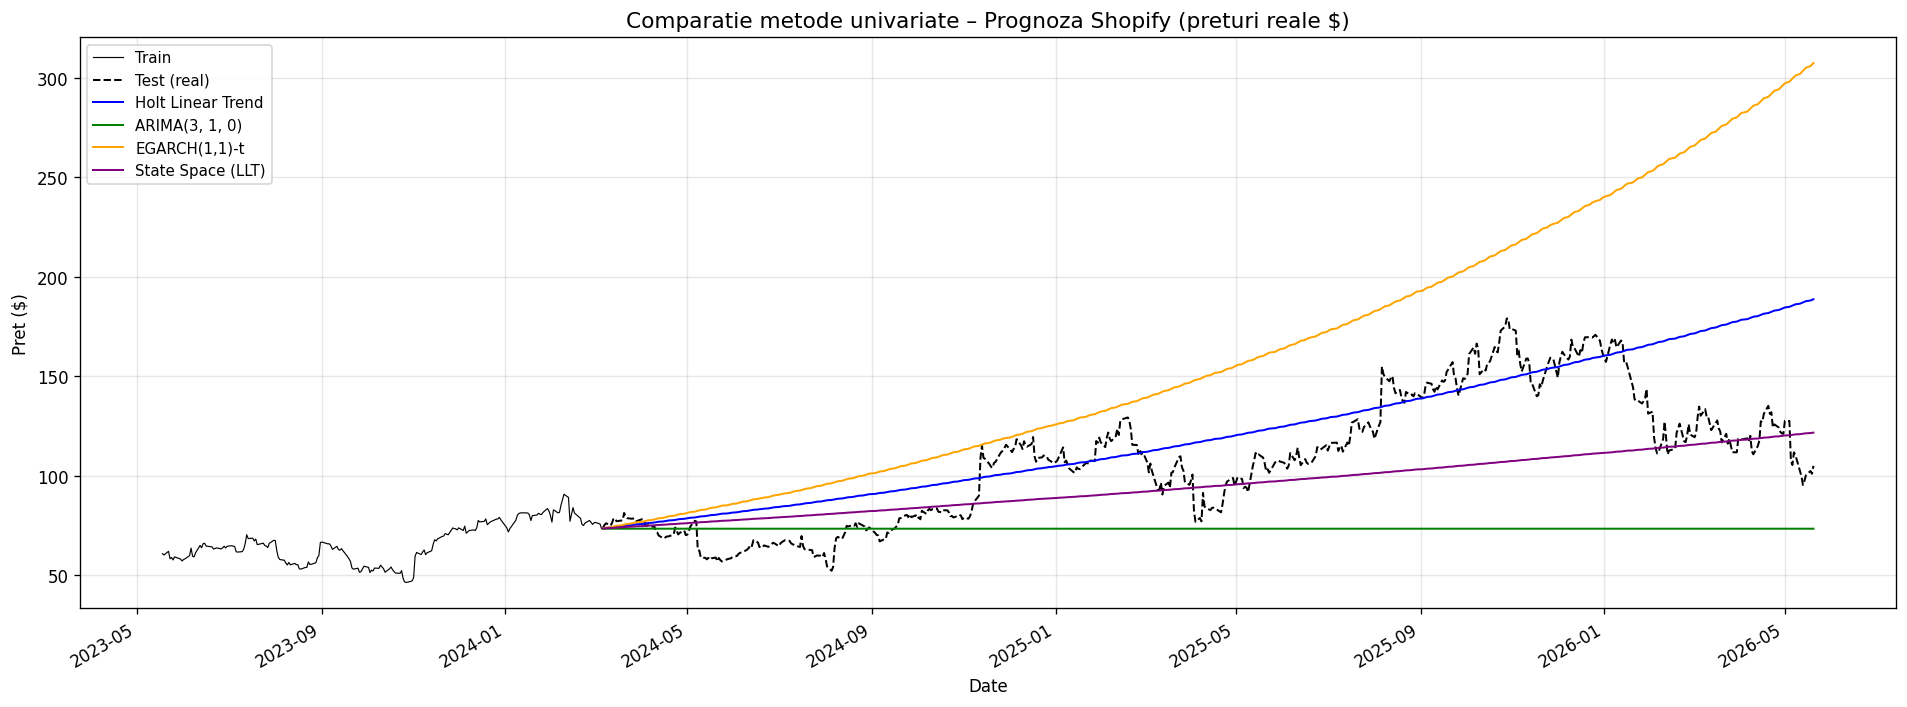

In [34]:
# Grafic comparativ – toate prognozele pe setul de test
fig, ax = plt.subplots(figsize=(16, 6))
np.exp(log_train.iloc[-200:]).plot(ax=ax, color="black", linewidth=0.7, label="Train")
price_test.plot(ax=ax, color="black", linewidth=1.2, linestyle="--", label="Test (real)")
fc_holt_price.plot(ax=ax,  color="blue",   linewidth=1.2, label="Holt Linear Trend")
fc_arima_price.plot(ax=ax, color="green",  linewidth=1.2, label=f"ARIMA{best_order}")
ax.plot(price_test.index[:h], fc_egarch_price[:h], color="orange",
        linewidth=1.2, label="EGARCH(1,1)-t")
fc_ss_price.plot(ax=ax, color="purple", linewidth=1.2, label="State Space (LLT)")
ax.set_title("Comparatie metode univariate – Prognoza Shopify (preturi reale $)", fontsize=13)
ax.set_ylabel("Pret ($)"); ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()


## 12. Concluzii Generale

### Caracterizarea seriei Shopify (SHOP)

| Proprietate | Rezultat | Test/Metodă |
|-------------|----------|-------------|
| Integrare | **I(1)** — random walk | ADF, KPSS (unanim) |
| Ruptură structurală | **Ian. 2022** (corecție tech) | Zivot-Andrews |
| Sezonalitate | **Absentă** | STL (forță = 0.000), spectru |
| Efecte ARCH | **Prezente** (puternic) | ARCH-LM (p ≈ 0) |
| Cozi groase | **Prezente** | Jarque-Bera (toate modelele) |
| Efect de levier | **Nesemnificativ** statistic | Sign Bias Test (p = 0.79) |

---

### Performanța modelelor

| Model | MAE ($) | RMSE ($) | MAPE (%) | AIC | Obiectiv optim |
|-------|---------|---------|---------|-----|----------------|
| State Space (LLT) | **19.77** | **26.08** | **16.94** | −8126.98 | Prognoza prețului |
| Holt Linear Trend | 19.54 | 26.56 | 19.88 | — | Prognoza rapidă |
| ARIMA(3,1,0) | 37.69 | 47.21 | 30.29 | −8145.09 | Structură liniară |
| EGARCH(1,1)-t | 55.56 | 73.38 | 50.28 | **11589.7** | **Volatilitate/Risc** |

---

### Observații metodologice finale

- Seria Shopify este **dominată de trendul stochastic** (random walk cu drift) — prognozele pe termen lung au incertitudine intrisecă ridicată
- **SARIMA nu a fost aplicat** — sezonalitatea este absentă empiric (STL + spectru)
- **EGARCH(1,1)-t este modelul optim** pentru distribuția condiționată a rentabilităților (AIC cel mai mic), recomandat pentru aplicații de risc financiar (Value-at-Risk, Expected Shortfall)
- **State Space LLT** oferă cea mai bună prognoză a prețului absolut (MAPE = 16.94%) și cea mai intuitivă interpretare economică
- **Modelele GARCH** nu sunt concepute pentru prognoza prețului — MAPE ridicat al EGARCH nu reflectă calitatea modelului, ci diferența de obiective

---

> **Limitări:** Toate modelele univariate ignoră variabilele macro-economice (politica Fed, indicii de sentiment, volumul tranzacțiilor) care pot îmbunătăți semnificativ prognoza — motivație pentru abordarea multivariată (VAR, VECM, ARDL).
